# Powerset Validation Cache Benchmarks

**Thesis tested**: exact, differentiable attention over many subsets of a set becomes cheaper than off the shelf direct computation when the subsets are processed in an imposed canonical order (sorted, each prefix before its extensions) through a prefix tree, or trie. Shared prefix states are computed once in the forward pass, and gradients flow through the shared structure in the backward pass. Reuse depends on the selected family and its canonical prefix structure; on large sets with shared prefixes it becomes faster training.

**In plain terms**: a model that looks at many combinations of the same facts repeats work. The combinations {A, B, C} and {A, B, D} both begin with {A, B}. Sorting the combinations into one fixed order and storing them in a prefix tree lets every shared beginning be computed once and reused. The answer agrees with direct computation to within rounding; only the repeated work is removed.

**Findings (RTX 2080 SUPER, float32)**

| Claim | Result |
|---|---|
| C1 exactness | Outputs and gradients agree with every direct method within the stated tolerances: 1024 of 1024 comparisons, float64 error at most 3.1e-13 |
| C3 speed, attention only | `powerset_runs` 1.46x to 2.08x faster than the fastest direct configuration at n 300 and 496 |
| C3 speed, complete training step | `powerset_runs` 1.29x to 1.92x; `run_based` at n 496 1.24x to 1.31x |
| C4 reuse | `powerset_runs` within 4.5% of the full power set node to fact ratio at the measured coverage points; equal to it at full coverage |
| C5 sampler validity | Every subset equally likely to be chosen, in all 216 certified cases |
| Counting theorems | Fixed size sweep nodes C(n + 1, k) − 1 and power set nodes 2^n − 1 at n 2 to 12; every nonwrapping contiguous run has exactly P + |f| − 1 nodes (523,776 runs at n 10, 0 violations); wrapping runs checked separately against the two segment bound |
| Limits | No memory advantage. The cache is slower at n 14 and 16, for `run_based` at n 300 and for `uniform_powerset`. A run's node to fact ratio depends on where it sits in the order (the last 1,000 subsets at n 100: 10.1 times the full power set ratio; short runs at the start of the order sit below it) |

**Cells**

| Cell | Content |
|---|---|
| V2C0 | Contract: claims, methods, samplers, experiments, measurement rules |
| V2C1 | Environment record and exactness certification |
| V2C2 | Sampler fairness certification; work sharing at benchmark scale |
| V2C3a | Speed and memory on large sets (n 300 and 496) |
| V2C3b | Work sharing and speed across coverage on small sets (n 14 and 16), up to every possible subset |
| V2C4 | Complete training step of a real model on real filings |
| V2C5 | Figures and claims |
| V2C6 | Counting checks for the prefix theorems by deterministic enumeration (CPU, no measurement) |

## Record for the paper

This notebook is standalone: every number the paper takes from the 2080 benchmarks and the counting checks is printed by a cell here, and the measurements are saved in one results file. Nothing refers to another notebook.

| Paper claim | Cell | Key numbers |
|---|---|---|
| C1 agreement of the cache with direct attention (`sdpa_masked`, `sdpa_masked_math`, `direct_gathered`, at every chunk size) within tolerance | V2C1 | 1,024 comparisons, 0 failures; float64 outputs within 1.7e-14, gradients within 3.1e-13; float32 gradients within 2.2e-6 relative (tolerance 1e-3) |
| C1 agreement through a complete training step on real filings | V2C4 | every configuration that fit matched the reference loss and gradients within tolerance; largest gradient relative difference 4.0e-7 |
| C5 the `powerset_runs` sampler is fair | V2C2 | 216 cases, n 2 to 8, every offset: inclusion probability exactly P / T |
| C4 reuse depends on the selected family and its prefix structure | V2C2, V2C3b | `powerset_runs` L 10n within 1% to 6% of the full power set ratio at n 105 to 496 at requested M 64,000 (n 496: 0.00428 against 0.00403, a coverage of about 2.9e-145); within 4.5% at every measured partial coverage on n 14 and 16; equal to the counting formula at full coverage; `uniform_powerset` 0.95 to 0.97 at n 300 and 496 |
| Counting checks: Theorem 2 (fixed size sweep), Theorem 3 (power set), Theorem 4 (nonwrapping contiguous run equality), wrapping runs, and the expected cardinality identity | V2C6 | order identical to `unrank_lex_subset` at n 2 to 12; Theorems 2 and 3 exact at n 2 to 12; N(run) = P + |f| − 1 for all 523,776 nonwrapping runs at n 10 and for first and last runs at n 10, 16, 20 and n 100; wrapping runs within the two segment bound (not an equality claim); expected summed cardinality of a run of L under a uniform offset equals L divided by the full power set ratio at every n and L; the ratio of means stays below the ratio of expectations bound while the maximum realized ratio exceeds it from L 8 |
| C3 speed, attention only | V2C3a | `powerset_runs` 1.46x to 2.08x over the fastest direct configuration at n 300 and 496, M 64,000 and 112,000 (n 496, M 112,000: 190.6 ms against 396.5 ms); `run_based` 1.27x to 1.28x at n 496 and 0.86x at n 300; `uniform_powerset` 0.025x to 0.032x and out of memory at M 112,000; the cache slower at every point on n 14 and 16 (0.16x to 0.90x) |
| C3 speed, complete training step | V2C4 | `powerset_runs` 1.29x to 1.92x at all 8 points (n 496, M 109,120 subsets: 238.0 ms against 457.9 ms); `run_based` n 496 1.24x to 1.31x |
| C2 memory | V2C3a, V2C4 | not supported: the cache's total peak is above the fastest direct configuration at every large set point (1.2x to 2.5x for `powerset_runs`) and above the lowest memory direct configuration at every point |

**Implementation measured here.** The `cache` configuration in every timed cell is the library's trie evaluator in `set_attention_cache.py` with gradients by the implementation described in V2C0, as frozen at hash f53957e0033d0c72; the masked concept notebook measures a different pair of walks (`mc_walk`, `mc_walk_jump` in `masked_concept_model.py`) with autograd, and the paper names each where it is used.

**Results file.** `pvcb_results_v2.pkl.lz4` in the notebook folder, written by V2C1 to V2C4 and read by V2C5 (no new measurement in V2C5). Every timed repeat, every certification row and the environment record are in it. V2C6 writes nothing; its output is the printed tables.

**Environment (V2C1).** Python 3.12.7, numpy 1.26.4, pandas 2.2.2, torch 2.5.1+cu121, CUDA 12.1, cuDNN 90100, Windows 10 19045; RTX 2080 SUPER, 8,192 MiB, capability 7.5; SDPA flash, memory efficient, math and cuDNN backends enabled; seed 367. Library hashes checked by every later cell: `set_attention_cache` f53957e0033d0c72, `set_attention_model` 647b44ba68fe9dd4, `set_attention_data` 9ea47fe86942f3b6, `set_attention_bench` bb6728c9438c02d5.

**Measurement rules (V2C0).** Asynchronous CUDA launches verified before any timing and recorded in V2C4; 2 untimed warmups then 5 timed repeats, median reported and every repeat saved; peak memory reset between configurations; out of memory recorded as a result, never retried; every comparison against the fastest of the 12 direct configurations at that point; favorable and unfavorable points both reported.ed.favorable and unfavorable points both reported.

## V2C0. Contract

### Claims

| ID | Claim | In plain terms | Measured in |
|---|---|---|---|
| C1 | Exactness: the cache produces the same outputs and gradients as direct computation | The shortcut does not change the answer or the training signal | V2C1, V2C4 |
| C2 | Memory: lower total peak GPU memory than direct computation | It needs less GPU memory | V2C3a |
| C3 | Time: faster than the fastest direct configuration | It finishes sooner than the best standard method | V2C3a, V2C3b, V2C4 |
| C4 | Reuse: trie nodes per summed subset fact approaches the exhaustive ratio | How much work is shared; lower means more sharing | V2C2, V2C3b |
| C5 | Sampler validity: every nonempty subset has inclusion probability exactly P / T | The sample is fair: no subset is favored | V2C2 |

Not claimed: any predictive benefit; results beyond the measured grid, hardware and implementations; that reuse automatically means speed (C4 and C3 are reported side by side).

### Terms

| Term | Meaning |
|---|---|
| n | Number of facts in the set |
| T | Number of possible nonempty subsets, 2^n − 1 |
| M, P | Requested and actual number of subsets processed |
| Coverage | P / T, the fraction of all possible subsets processed |
| Canonical order | One fixed sorted order of all subsets in which every subset comes right after its prefix (depth first) |
| Trie node | One computed prefix state; shared prefixes are stored once |
| nodes / facts | Trie nodes divided by the total facts across all subsets: 1 means no sharing, lower means more sharing |
| Exhaustive ratio | (2^n − 1) / (n × 2^(n−1)), the nodes / facts value when every subset is processed (about 2 / n) |
| speedup_vs_best | Fastest direct time / cache time; above 1 means the cache is faster |

### Methods compared

Inputs: one query q [C, d] and facts K, V [n, C, d], C = 24 channels, d = 80, drawn from a seeded standard normal (seed 367 + n).

| Method | What it does |
|---|---|
| `cache` | The invention: walks the trie once, extending each shared prefix by one fact, then walks it in reverse for gradients |
| `sdpa_masked` | PyTorch's standard attention (`scaled_dot_product_attention`) over all n facts, with a mask hiding facts outside each subset; default backend |
| `sdpa_masked_math` | The same call forced to PyTorch's reference math backend |
| `direct_gathered` | Copies each subset's facts out and runs attention on them separately |
| Chunking | Each direct method is run on all subsets at once and in batches of 4096, 1024 and 256 subsets, which trades speed for memory |

13 configurations in total: `cache` plus 3 direct methods × 4 batch sizes. Every comparison is against the fastest of the 12 direct configurations at that point.

### Samplers

Every sample is sorted into canonical order before processing, so every shared prefix is merged.

| Sampler | Selection | In plain terms |
|---|---|---|
| `uniform_powerset` | Single subsets at a fixed stride ceil(T / M) across the canonical order, from a random start | Fair, but the chosen subsets are far apart and rarely share prefixes |
| `run_based` | Runs of 8 neighboring subsets within sizes 4, 8, 16, 32 and 64 | Small groups of similar subsets of chosen sizes |
| `powerset_runs` | Evenly spaced starting points, each followed for L consecutive subsets in canonical order; the pattern is shifted by a random offset, so every subset has inclusion probability exactly P / T. L = n or 10n | Fair like `uniform_powerset`, but each pick brings its neighbors, which share prefixes |

### Experiments

| Cell | Points | Purpose |
|---|---|---|
| V2C1 | All 13 configurations, float64 and float32, CPU and GPU, all samplers | Certify exactness before any timing |
| V2C2 | Fairness: n 2 to 8, every possible offset. Sharing: n 16, 105, 300, 496 at M 64,000 | Prove the sampler is fair; measure sharing at scale |
| V2C3a | n {300, 496} × M {64,000, 112,000} × 4 sampler settings × 13 configurations | Speed and memory on large sets |
| V2C3b | n {14, 16} × coverage {1/16, 1/8, 1/4, 1/2, 1} × {`uniform_powerset`, `powerset_runs` L = 10n} | How sharing and speed change with coverage, up to every possible subset |
| V2C4 | Every sampler and n with a cache speedup in V2C3a, at both M | Whether the speedup survives a complete training step |

### Complete training step (V2C4)

In plain terms: one full training update of a real model on a real financial filing, not just the attention operation.

| Item | Setting |
|---|---|
| Data | One real filing per step, with the fact count nearest n (300 or 496); every fact kept |
| Model | Pretrained set encoder (`SemanticMaskedSetEncoder`, training mode) followed by a subset interaction head (`SubsetInteractionStack`, hidden 256) |
| Loss | Huber loss, 0.5 × full set + 0.5 × mean over subsets; target 0 (only time is measured) |
| Update | Backward pass and one AdamW step (learning rate 1e-4 head, 1e-5 encoder, weight decay 0.01) |
| Fairness | Model, optimizer and random states restored before every step; every configuration must reproduce the same loss and gradients before it is timed |

### Correctness tolerances

| Precision | Passes when |
|---|---|
| float64 | Outputs and gradients differ by at most 1e-9 + 1e-9 × the largest reference value |
| float32 | Outputs within 1e-6 + 1e-4 × the largest reference value; gradient relative difference at most 1e-3 |

### Measurement rules

- GPU launches are asynchronous, as in normal training. The setup cell checks this before any cell runs and stops if it fails; V2C4 repeats the check and records it.
- Each configuration: 2 untimed warmups, then 5 timed repeats; the median is reported and every repeat is saved.
- GPU memory is cleared and peak statistics are reset between configurations. Memory is the total peak allocated.
- Out of memory is recorded as a result, never retried.
- Favorable and unfavorable points are both reported. Memory is compared against both the fastest and the lowest memory direct configuration.

### Output

One results file, `pvcb_results_v2.pkl.lz4`, in the notebook folder.

In [2]:
# Setup (first cell). CUDA launches must be asynchronous for every timing in this notebook
# (V2C0 Amendment 4): CUDA_LAUNCH_BLOCKING is never set, and the launch mode is checked.
import os, sys, time
os.environ["ENV"] = "prod"
os.environ.pop("CUDA_LAUNCH_BLOCKING", None)
sys.path.insert(0, r"E:\apriori-ml")
sys.path.insert(0, r"C:\Users\jakem\Documents\Belk\Sec\Bloomberg Pipeline v1\BB_Pipeline_v15")
import torch
A = torch.randn(4096, 4096, device="cuda"); Bm = torch.randn(4096, 4096, device="cuda"); Cm = torch.empty_like(A)
torch.mm(A, Bm, out=Cm); torch.cuda.synchronize()
e0, e1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
e0.record(); t0 = time.perf_counter()
for _ in range(16):
    torch.mm(A, Bm, out=Cm)
issue_ms = 1000 * (time.perf_counter() - t0); e1.record(); torch.cuda.synchronize()
gpu_ms = e0.elapsed_time(e1)
del A, Bm, Cm; torch.cuda.empty_cache()
print(f"launch mode check: 16 matrix multiplies, host issue {issue_ms:.2f} ms, GPU {gpu_ms:.2f} ms")
assert "CUDA_LAUNCH_BLOCKING" not in os.environ and issue_ms < 0.1 * gpu_ms, \
    "CUDA launches are synchronous: restart the kernel and run this cell first"

launch mode check: 16 matrix multiplies, host issue 0.42 ms, GPU 224.68 ms


## V2C1. Environment record and exactness certification

Certifies claim C1 before any timing. Every method and batch size is run on 16 test workloads covering all three samplers, and its outputs and its gradients for q, K and V are compared with a float64 reference (`sdpa_masked_math`, all subsets at once, same device). Tolerances are those in V2C0.

**In plain terms**: before anything is timed, every method must be shown to give the same answer and the same training signal as the reference, on the CPU and on the GPU, in double and single precision. The test workloads include the awkward cases: repeated facts, subsets that end partway down the tree, single fact subsets, and large query scales that stress the softmax. Batch sizes 64 and 7 are tested on top of the benchmark's 4096, 1024 and 256, and at least one workload per sampler exceeds 4096 subsets, so every batch size actually splits a workload. The cell stops unless every float64 configuration and every GPU float32 configuration passes, including all 13 benchmark configurations.

**Printed output, in order**

**V2C1: ENVIRONMENT**

| Label | Meaning |
|---|---|
| python, numpy, pandas, torch | Versions |
| cuda_runtime, cudnn | CUDA runtime and cuDNN versions |
| platform | Operating system |
| seed, key_tag | 367, "pvcb" |
| library_sha16 | Source hashes of the library files; later cells stop if these change |
| gpu, gpu_memory_MiB, gpu_capability | The GPU |
| sdp_enabled_flags | Which PyTorch attention backends are enabled |

**V2C1: CERTIFICATION WORKLOADS**

| Label | Meaning |
|---|---|
| case | Workload description |
| sampler | `uniform_powerset`, `run_based` or `powerset_runs` |
| run_len | Run length L (`powerset_runs` only; None otherwise) |
| set_sizes | Facts per set (several sets means mixed sizes, concatenated) |
| M | Subsets requested per set |
| subsets | Actual subsets P |
| trie_nodes | Prefix states the cache computes |
| subset_facts | Total facts across all subsets |
| depth | Trie levels |
| q_scale | Query scale (4 stresses the softmax) |
| repeated_facts | True if some fact appears at several trie nodes |
| internal_terminals | True if some subset ends at an internal trie node |
| single_fact_subsets | True if some subset has one fact |

**V2C1: EQUIVALENCE** (comparison count and minutes in the header)

| Label | Meaning |
|---|---|
| device, dtype, impl, chunk | The configuration |
| cases | Workloads compared |
| ok, fail, unsupported | Count by outcome |
| max_err_out | Largest absolute output difference |
| max_err_grad_q, max_err_grad_K, max_err_grad_V | float64: largest absolute gradient difference; float32: norm of difference / norm of reference |

**V2C1: SDPA BACKEND EXECUTED**: device, impl, executed_backend (the attention kernel PyTorch actually ran, as recorded by the profiler), cases.

**V2C1: CERTIFICATION BY CONFIGURATION**: rows device, dtype, impl; columns chunk. Each cell reads certified, FAILED, not certified (unsupported), or not chunked (`cache`).

**UNSUPPORTED** and **FAILURES**: printed only if any occurred, with the configuration and case.

**EARLIER MEASUREMENTS**: whether a previous run's results were found in the results file and kept, or removed because the environment or library changed.

**V2C1 CERTIFICATION PASSED**: comparisons within tolerance, failures (0), unsupported, required configurations certified, total certified configurations (including the 13 benchmark configurations), and the results file.

In [3]:
# V2C1. Environment record and exactness certification (claim C1), before any timing.
# Inputs q [C, d], K [N, C, d], V [N, C, d] (C = 24, d = 80), drawn in float64 and cast; loss sum(W * out).
# Every implementation and chunk size is compared, on outputs and on gradients for q, K and V, against the
# float64 unchunked sdpa_masked_math reference on the same device, with the tolerances in V2C0. Values must be
# finite before comparison; unsupported implementations are recorded, never skipped. The SDPA kernel actually
# executed is recorded with the profiler. Chunk sizes: all, 4096, 1024, 256 (benchmark) plus 64 and 7; one case
# per sampler exceeds 4096 subsets, so every chunk size splits a workload of each sampler.
# Gate: every float64 configuration (CPU, GPU) and every cuda float32 configuration must pass every case,
# including all 13 benchmark configurations; otherwise the cell stops.

import sys, os, gc, hashlib, inspect, platform, importlib, time
LIB_DIR = r"E:\apriori-ml"
if LIB_DIR not in sys.path:
    sys.path.insert(0, LIB_DIR)
import numpy as np
import pandas as pd
import torch
import set_attention_cache, set_attention_model, set_attention_data, set_attention_bench
for _m in (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench):
    importlib.reload(_m)
import set_attention_bench as B
from apriori.serialization import save_to_pickle, load_from_pickle

RESULTS = r"E:\apriori-ml\notebooks\pvcb_results_v2.pkl.lz4"
C_CH, D_HEAD = 24, 80
CERT_CHUNKS = (4096, 1024, 256, 64, 7)
TOL64 = (1e-9, 1e-9)                      # absolute, relative to max abs reference
TOL32_OUT = (1e-6, 1e-4)
TOL32_GRAD, TOL32_ZERO = 1e-3, 1e-6
TOL64_ZERO = 1e-9
assert torch.cuda.is_available(), "PVCB benchmarks run on the GPU: CUDA is required"
DEVICES = ["cpu", "cuda"]

def sha16(s):
    return hashlib.sha256(s.encode()).hexdigest()[:16]

# ----- environment record -----
env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
       "cudnn": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
       "platform": platform.platform(), "seed": B.SEED, "key_tag": B.KEY_TAG,
       "library_sha16": {m.__name__: sha16(inspect.getsource(m)) for m in
                         (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench)}}
if torch.cuda.is_available():
    pr = torch.cuda.get_device_properties(0)
    env.update({"gpu": pr.name, "gpu_memory_MiB": round(pr.total_memory / 2**20),
                "gpu_capability": f"{pr.major}.{pr.minor}",
                "sdp_enabled_flags": {"flash": torch.backends.cuda.flash_sdp_enabled(),
                                      "mem_efficient": torch.backends.cuda.mem_efficient_sdp_enabled(),
                                      "math": torch.backends.cuda.math_sdp_enabled(),
                                      "cudnn": getattr(torch.backends.cuda, "cudnn_sdp_enabled", lambda: None)()}})

# ----- certification workloads -----
# (label, set sizes, M, sampler, query scale, run_len for powerset_runs)
CASES = [("all subsets of 5 facts (singletons, internal terminals, the full set)", [5], 31, "uniform_powerset", 1.0, None),
         ("12 facts, power set", [12], 300, "uniform_powerset", 1.0, None),
         ("12 facts, run based", [12], 300, "run_based", 1.0, None),
         ("12 facts, power set runs, L 12", [12], 300, "powerset_runs", 1.0, 12),
         ("mixed set sizes 3, 17, 40, power set", [3, 17, 40], 200, "uniform_powerset", 1.0, None),
         ("mixed set sizes 3, 17, 40, run based", [3, 17, 40], 200, "run_based", 1.0, None),
         ("mixed set sizes 3, 17, 40, power set runs, L 10 (3 facts: every subset)", [3, 17, 40], 200,
          "powerset_runs", 1.0, 10),
         ("64 facts, power set, query scale 4", [64], 500, "uniform_powerset", 4.0, None),
         ("64 facts, run based, query scale 4", [64], 500, "run_based", 4.0, None),
         ("64 facts, power set runs, L 64, query scale 4", [64], 500, "powerset_runs", 4.0, 64),
         ("105 facts, power set", [105], 2000, "uniform_powerset", 1.0, None),
         ("105 facts, run based", [105], 2000, "run_based", 1.0, None),
         ("105 facts, power set runs, L 105", [105], 2000, "powerset_runs", 1.0, 105),
         ("105 facts, power set, 5,000 subsets (splits at chunk 4096)", [105], 5000, "uniform_powerset", 1.0, None),
         ("105 facts, run based, 5,000 subsets (splits at chunk 4096)", [105], 5000, "run_based", 1.0, None),
         ("105 facts, power set runs, L 1050, 5,000 requested (4,200 actual; splits at chunk 4096)", [105], 5000,
          "powerset_runs", 1.0, 1050)]
workloads = []
for k, (label, ns, M, smp, qs, rl) in enumerate(CASES):
    wl = B.make_workload(ns, M, smp, tag=f"_cert{k}", run_len=rl)
    pos = [np.asarray(t["pos"]) for t in wl["tries"] if t is not None]
    term = [set(np.asarray(t["terminals"]).tolist()) & set(np.asarray(t["parent"]).tolist())
            for t in wl["tries"] if t is not None]
    wl.update({"label": label, "q_scale": qs, "seed": B.SEED + k,
               "repeated_facts": any(len(p_) > len(set(p_.tolist())) for p_ in pos),
               "internal_terminals": any(len(x) > 0 for x in term),
               "single_fact_subsets": any(len(S) == 1 for S in wl["subs"])})
    workloads.append(wl)
assert any(w["repeated_facts"] for w in workloads), "no workload with a fact at several trie nodes"
assert any(w["internal_terminals"] for w in workloads), "no workload with terminals at internal nodes"
assert any(w["single_fact_subsets"] for w in workloads), "no workload with single fact subsets"
assert any(len(w["ns"]) > 1 for w in workloads), "no mixed set size workload"
for _smp in ("uniform_powerset", "run_based", "powerset_runs"):
    assert any(w["P"] > max(CERT_CHUNKS) and w["sampler"] == _smp for w in workloads), \
        f"no {_smp} workload with more subsets than the largest chunk size ({max(CERT_CHUNKS)})"

def is_unsupported(e):
    msg = str(e).lower()
    return isinstance(e, (RuntimeError, NotImplementedError)) and any(
        s in msg for s in ("no available kernel", "not implemented", "not supported", "unsupported"))

def run_cfg(impl, chunk, wl, dtype, device):
    """(outputs, gq, gK, gV) as float64 CPU tensors, or the exception."""
    q, K, V = B.make_inputs(wl["N"], C_CH, D_HEAD, wl["seed"], dtype, device, wl["q_scale"])
    W = B.make_weights(wl["P"], C_CH, D_HEAD, wl["seed"], dtype, device)
    out = B.run_attention(impl, q, K, V, wl, W, chunk=chunk)
    res = [out.detach().double().cpu()] + [t.grad.detach().double().cpu() for t in (q, K, V)]
    del q, K, V, W, out
    return res

def compare(res, ref, dtype):
    """Per tensor errors and the pass flag under the contract's tolerances; finite guards first."""
    names = ("out", "grad_q", "grad_K", "grad_V")
    for nm, a in zip(names, res):
        if not bool(torch.isfinite(a).all()):
            return {"pass": False, "note": f"nonfinite {nm}"}
    row, ok = {}, True
    for nm, a, b in zip(names, res, ref):
        diff = a - b
        mad, mref = float(diff.abs().max()), float(b.abs().max())
        nd, nr = float(diff.norm()), float(b.norm())
        if not all(np.isfinite([mad, mref, nd, nr])):
            return {"pass": False, "note": f"nonfinite error or norm in {nm}"}
        if dtype == torch.float64:
            err = mad
            ok_t = mad <= TOL64[0] + TOL64[1] * mref
            if nm != "out" and nr == 0.0:
                ok_t = nd <= TOL64_ZERO
        elif nm == "out":
            err = mad
            ok_t = mad <= TOL32_OUT[0] + TOL32_OUT[1] * mref
        else:
            err = nd / nr if nr > 0 else nd
            ok_t = (nd / nr <= TOL32_GRAD) if nr > 0 else (nd <= TOL32_ZERO)
        row[f"err_{nm}"] = err
        ok = ok and ok_t
    row["pass"] = ok
    return row

rows1, backends = [], []
t0 = time.perf_counter()
for device in DEVICES:
    for wi, wl in enumerate(workloads):
        ref = run_cfg("sdpa_masked_math", None, wl, torch.float64, device)
        for t in ref:
            assert bool(torch.isfinite(t).all()), f"nonfinite float64 reference: {wl['label']} on {device}"
        cfgs = [(torch.float64, i, c) for i in ("cache", "sdpa_masked_math", "direct_gathered")
                for c in ([None] if i == "cache" else [None, *CERT_CHUNKS])]
        cfgs += [(torch.float32, i, c) for i in B.IMPLS
                 for c in ([None] if i == "cache" else [None, *CERT_CHUNKS])]
        for dtype, impl, chunk in cfgs:
            base = {"device": device, "dtype": str(dtype).replace("torch.", ""), "case": wl["label"],
                    "sampler": wl["sampler"], "P": wl["P"], "impl": impl,
                    "chunk": "all" if chunk is None else chunk}
            try:
                r = compare(run_cfg(impl, chunk, wl, dtype, device), ref, dtype)
                rows1.append({**base, "status": "ok" if r.get("pass") else "FAIL", **r})
            except Exception as e:
                if is_unsupported(e):
                    rows1.append({**base, "status": "unsupported", "pass": None,
                                  "note": f"{type(e).__name__}: {str(e)[:120]}"})
                else:
                    raise
        q, K, V = B.make_inputs(wl["N"], C_CH, D_HEAD, wl["seed"], torch.float32, device, wl["q_scale"])
        m_all = B.subset_mask(wl["subs"], wl["N"], device)
        for impl in ("sdpa_masked", "sdpa_masked_math"):
            try:
                ex = B.sdpa_executed_backend(q, K, V, m_all, impl == "sdpa_masked_math")
            except Exception as e:
                if not is_unsupported(e):
                    raise
                ex = f"unsupported ({type(e).__name__})"
            backends.append({"device": device, "case": wl["label"], "dtype": "float32", "impl": impl,
                             "executed_backend": ex})
        del q, K, V, m_all
        del ref
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()
mins1 = (time.perf_counter() - t0) / 60

eq = pd.DataFrame(rows1)
bk = pd.DataFrame(backends)
n_fail = int((eq["status"] == "FAIL").sum())
n_uns = int((eq["status"] == "unsupported").sum())
cfg_keys = ["device", "dtype", "impl", "chunk"]
cfg_status = (eq.groupby(cfg_keys, sort=False)["status"]
                .agg(lambda s: "certified" if (s == "ok").all() else
                     ("FAILED" if (s == "FAIL").any() else "not certified (unsupported)"))
                .rename("certification").reset_index())
required = cfg_status[(cfg_status["dtype"] == "float64") |
                      ((cfg_status["device"] == "cuda") & (cfg_status["dtype"] == "float32"))]
missing_req = required[required["certification"] != "certified"]
certified = [tuple(r) for r in cfg_status[cfg_status["certification"] == "certified"][cfg_keys].itertuples(index=False)]
BENCH_CONFIGS = [("cuda", "float32", "cache", "all")] + [("cuda", "float32", i, c)
                 for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered") for c in ("all", 4096, 1024, 256)]
missing_bench = [c for c in BENCH_CONFIGS if c not in set(certified)]

print("V2C1: ENVIRONMENT")
for k, v in env.items():
    print(f"  {k}: {v}")
print(f"\nV2C1: CERTIFICATION WORKLOADS (C = {C_CH}, d = {D_HEAD}):")
print(pd.DataFrame([{"case": w["label"], "sampler": w["sampler"], "run_len": w["run_len"], "set_sizes": w["ns"],
                     "M": w["M"],
                     "subsets": w["P"], "trie_nodes": w["nodes"], "subset_facts": w["facts"],
                     "depth": w["depth"], "q_scale": w["q_scale"], "repeated_facts": w["repeated_facts"],
                     "internal_terminals": w["internal_terminals"],
                     "single_fact_subsets": w["single_fact_subsets"]} for w in workloads]).to_string(index=False))
print(f"\nV2C1: EQUIVALENCE vs the float64 unchunked sdpa_masked_math reference on the same device "
      f"({len(eq)} comparisons, {mins1:.1f} min): summary by device, precision, implementation, chunk")
summ = (eq.assign(ok=eq["status"] == "ok", fail=eq["status"] == "FAIL", uns=eq["status"] == "unsupported")
          .groupby(["device", "dtype", "impl", "chunk"], sort=False)
          .agg(cases=("case", "size"), ok=("ok", "sum"), fail=("fail", "sum"), unsupported=("uns", "sum"),
               max_err_out=("err_out", "max"), max_err_grad_q=("err_grad_q", "max"),
               max_err_grad_K=("err_grad_K", "max"), max_err_grad_V=("err_grad_V", "max"))
          .reset_index())
print(summ.to_string(index=False))
print("\nV2C1: SDPA BACKEND EXECUTED (profiler, float32, gradient enabled, per case):")
print(bk.groupby(["device", "impl", "executed_backend"]).size().rename("cases").reset_index().to_string(index=False))
print("\nV2C1: CERTIFICATION BY CONFIGURATION (certified = every case passed):")
print(cfg_status.pivot_table(index=["device", "dtype", "impl"], columns="chunk", values="certification",
                             aggfunc="first").fillna("not chunked").to_string())
if n_uns:
    print("\nUNSUPPORTED (recorded, not skipped):")
    print(eq[eq["status"] == "unsupported"][["device", "dtype", "impl", "chunk", "case", "note"]].to_string(index=False))
if n_fail:
    print("\nFAILURES:")
    print(eq[eq["status"] == "FAIL"].to_string(index=False))

CERT_KEYS = {"env", "equivalence", "sdpa_executed_backend_cert", "certification", "certified_configs",
             "cert_workloads"}
store = load_from_pickle(RESULTS) if os.path.exists(RESULTS) else {}
old_env = store.get("env")
same_env = old_env is not None and all(old_env.get(k) == env.get(k) for k in
                                       ("library_sha16", "torch", "cuda_runtime", "cudnn", "gpu", "platform"))
stale = [k for k in store if k not in CERT_KEYS] if not same_env else []
for k in stale:
    del store[k]
store.update({"env": env, "equivalence": eq, "sdpa_executed_backend_cert": bk,
              "certification": cfg_status, "certified_configs": certified,
              "cert_workloads": [{k: w[k] for k in ("label", "ns", "M", "sampler", "run_len", "P", "nodes", "facts",
                                                     "depth", "q_scale", "seed")} for w in workloads]})
tmp = RESULTS.replace(".pkl.lz4", ".tmp.pkl.lz4")
save_to_pickle(store, tmp, lz4_compression=True)
os.replace(tmp, RESULTS)
assert n_fail == 0, f"V2C1 CERTIFICATION FAILED: {n_fail} comparisons out of tolerance (see FAILURES)"
assert not missing_bench, f"V2C1 CERTIFICATION FAILED: benchmark configurations not certified: {missing_bench}"
assert missing_req.empty, ("V2C1 CERTIFICATION FAILED: required configurations not certified:\n"
                           + missing_req.to_string(index=False))
print(f"\nEARLIER MEASUREMENTS: {'none saved' if not old_env else ('kept (same environment and library source)' if same_env else 'INVALIDATED and removed: ' + (', '.join(stale) if stale else 'none present'))}")
print(f"\nV2C1 CERTIFICATION PASSED: {int((eq['status'] == 'ok').sum())} comparisons within tolerance, "
      f"0 failures, {n_uns} unsupported (recorded); every required configuration certified "
      f"({len(required)}: all float64 on CPU and GPU, all float32 on GPU); {len(certified)} certified "
      f"configurations saved, including all 13 benchmark configurations on cuda float32; every output, gradient, error and norm finite; "
      f"saved to {RESULTS}")

[edgar_xbrl_parser.py] Applied dynamic namespace mapping patch to xbrl.taxonomy and xbrl.instance
V2C1: ENVIRONMENT
  python: 3.12.7
  numpy: 1.26.4
  pandas: 2.2.2
  torch: 2.5.1+cu121
  cuda_runtime: 12.1
  cudnn: 90100
  platform: Windows-10-10.0.19045-SP0
  seed: 367
  key_tag: pvcb
  library_sha16: {'set_attention_cache': 'f53957e0033d0c72', 'set_attention_model': '647b44ba68fe9dd4', 'set_attention_data': '9ea47fe86942f3b6', 'set_attention_bench': 'bb6728c9438c02d5'}
  gpu: NVIDIA GeForce RTX 2080 SUPER
  gpu_memory_MiB: 8192
  gpu_capability: 7.5
  sdp_enabled_flags: {'flash': True, 'mem_efficient': True, 'math': True, 'cudnn': True}

V2C1: CERTIFICATION WORKLOADS (C = 24, d = 80):
                                                                                   case          sampler  run_len   set_sizes    M  subsets  trie_nodes  subset_facts  depth  q_scale  repeated_facts  internal_terminals  single_fact_subsets
                  all subsets of 5 facts (singletons, internal t

## V2C1 findings

**V2C1: ENVIRONMENT**

| Label | Value |
|---|---|
| python, numpy, pandas, torch | 3.12.7, 1.26.4, 2.2.2, 2.5.1+cu121 |
| cuda_runtime, cudnn | 12.1, 90100 |
| platform | Windows-10-10.0.19045-SP0 |
| seed, key_tag | 367, pvcb |
| library_sha16 | set_attention_cache f53957e0033d0c72; set_attention_model 647b44ba68fe9dd4; set_attention_data 9ea47fe86942f3b6; set_attention_bench bb6728c9438c02d5 (every later cell checks these) |
| gpu, gpu_memory_MiB, gpu_capability | NVIDIA GeForce RTX 2080 SUPER, 8192, 7.5 |
| sdp_enabled_flags | flash, mem_efficient, math and cudnn all enabled |

**V2C1: CERTIFICATION WORKLOADS**: 16 cases.

- Every awkward structure is covered: facts at several trie nodes (all 16 cases), subsets ending partway down the tree, single fact subsets, mixed set sizes (3, 17, 40), and query scale 4.
- Each sampler has a case above 4096 subsets (5,000; 5,000; 4,200 actual), so every chunk size splits a workload of each sampler.
- Actual P is below requested M only where the sampler's rules say so: stride rounding (12 facts, power set: 292 of 300) and dropped partial runs (`powerset_runs`: 448 of 500, 1,995 of 2,000, 4,200 of 5,000).
- Work sharing is already visible at 105 facts. `powerset_runs` (L 1050) needs 4,367 prefix states for 191,516 summed facts; `uniform_powerset` at 5,000 subsets needs 236,557 for 262,474.

**V2C1: EQUIVALENCE** (1,024 comparisons, 5.0 min): every row 16 of 16 ok, 0 fail, 0 unsupported.

| Precision | Largest error, all implementations and chunk sizes | Tolerance |
|---|---|---|
| float64 (CPU, GPU) | outputs 1.7e-14; gradients 3.1e-13 (largest absolute difference) | 1e-9 + 1e-9 × largest reference value |
| float32 (CPU, GPU) | outputs 4.7e-6 (largest absolute difference); gradients 2.2e-6 (relative) | outputs 1e-6 + 1e-4 × largest reference value; gradients 1e-3 |

- `cache` matches the reference on both devices and in both precisions. float64: outputs within 1.7e-14, gradients within 3.1e-13. float32 on the GPU: outputs within 2.3e-6, gradients within 8.4e-7.
- Every batched direct configuration matches its unbatched form at every chunk size down to 7, for all three samplers.
- In plain terms: the cache gives the same answer and training signal as standard attention to within rounding. float32 gradient errors are about 450x below the tolerance.

**V2C1: SDPA BACKEND EXECUTED**: on the GPU, `sdpa_masked` runs EFFICIENT_ATTENTION and `sdpa_masked_math` runs MATH in all 16 cases; on the CPU, FLASH_ATTENTION (cpu) and MATH.

**V2C1: CERTIFICATION BY CONFIGURATION**: every configuration is certified on both devices and in both precisions; `cache` is not chunked by design.

**EARLIER MEASUREMENTS**: kept (same environment and library source).

**V2C1 CERTIFICATION PASSED**: 1,024 comparisons within tolerance, 0 failures, 0 unsupported. All 45 required configurations are certified (26 float64 across CPU and GPU, 19 cuda float32). 64 certified configurations are saved, including all 13 benchmark configurations on cuda float32. Claim C1 holds for all three samplers, and timing may proceed.

## V2C2. Sampler fairness and work sharing

Certifies that `powerset_runs` is a fair sample (claim C5), then measures how much work each sampler lets the cache share (claim C4) at benchmark scale, before any timing. The cell runs on the CPU and stops if the library changed after V2C1.

**In plain terms**: `powerset_runs` picks evenly spaced starting points in the sorted list of all subsets and takes a run of neighbors from each. Parts (1) to (3) prove that every subset is equally likely to be chosen. Part (4) shows that the runs make the chosen subsets share their beginnings, so the cache does far less work than a sample of isolated subsets.

**Printed output, in order**

**(1) PASSED**: stepping from one subset to the next (`canonical_successor`) visits exactly the sorted order of all subsets (`unrank_lex_subset`) for n = 1 to 10, and stops after the last one. So a run's neighbors really are consecutive in the canonical order.

**(2) PASSED**: for n = 2 to 8, several budgets M and run lengths (1, 2, 3, 5, 8, 64), checked over every possible offset:

| Check | Meaning |
|---|---|
| each draw has exactly P = R × L distinct ranks | Runs never overlap and nothing is duplicated |
| every rank included in exactly P of the T rotations | With a random offset, every subset has inclusion probability exactly P / T |

The offset is drawn from seeded bytes with 64 guard bits, so its bias is below 2^−64.

**(3) PASSED**: the seeded sampler's actual output is sorted, distinct, of length P, and equal to one of the certified rotations; M ≥ T returns every subset in order.

**(4) REUSE**: requested M = 64,000, with the same sample keys as V2C3a.

| Label | Meaning |
|---|---|
| n | Facts in the set |
| sampler | `uniform_powerset`, `run_based` or `powerset_runs` |
| run_len | Run length L (`powerset_runs` only: n or 10n) |
| M_requested | Requested budget |
| P | Actual subsets |
| coverage | P / (2^n − 1) |
| nodes | Trie nodes: prefix states the cache computes |
| facts | Total facts across all subsets: the per fact work direct computation does |
| nodes_over_facts | nodes / facts: 1 means no sharing, lower means more sharing |
| exhaustive_ratio | (2^n − 1) / (n × 2^(n−1)): the value when every subset is processed, the best possible |
| depth | Trie levels |
| sample_s | Sampling time in seconds |

**Saved**: the certified cases under 'sampler_cert' and the sharing table under 'sampler_reuse'.

In [4]:
# V2C2. powerset_runs sampler: fairness certification (claim C5), then work sharing at benchmark scale (claim C4).
# (1) Stepping canonical_successor from the first subset reproduces unrank_lex_subset at every rank, n = 1 to 10.
# (2) For n = 2 to 8, several M and run lengths, over EVERY offset: each draw has exactly P = R x L distinct ranks,
#     and every rank is included in exactly P of the T rotations (inclusion probability exactly P / T).
# (3) The seeded sampler's output is one of those rotations; M >= T returns every subset in canonical order.
# (4) Sharing at n {16, 105, 300, 496}, requested M 64,000, for all four sampler settings, with the benchmark's keys.
# Saved under 'sampler_cert' and 'sampler_reuse'. Continues the V2C1 kernel; stops if the library changed.

import os, time, inspect
import numpy as np
import pandas as pd
from set_attention_cache import (unrank_lex_subset, powerset_total, canonical_successor, powerset_run_ranks,
                                 powerset_run_base, sample_subsets_powerset_runs, build_prefix_trie_canonical)
from apriori.serialization import save_to_pickle, load_from_pickle

_need = ("B", "RESULTS", "env", "sha16", "set_attention_cache", "set_attention_model", "set_attention_data",
         "set_attention_bench")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run V2C1 first"
store = load_from_pickle(RESULTS)
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in
           (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench)}
assert store["env"]["library_sha16"] == lib_now, "library source changed since V2C1 certification: rerun V2C1"

CERT_N = range(2, 9)
CERT_L = (1, 2, 3, 5, 8, 64)
REUSE_N, REUSE_M = (16, 105, 300, 496), 64000

def expand(n, runs):
    T = powerset_total(n)
    return [(s + t) % T for s, L in runs for t in range(L)]

# ===== (1) successor == unrank over the whole enumeration =====
for n in range(1, 11):
    T = powerset_total(n)
    S = unrank_lex_subset(0, n)
    for r in range(T):
        assert S == unrank_lex_subset(r, n), f"successor walk differs at n={n}, rank {r}"
        S = canonical_successor(S, n)
    assert S is None, f"successor past the last subset is not None (n={n})"
print("(1) PASSED: canonical_successor walks the entire canonical enumeration == unrank_lex_subset, "
      "n = 1..10; the successor of the last subset is None")

# ===== (2) exact inclusion over every offset =====
cert = []
for n in CERT_N:
    T = powerset_total(n)
    for M in sorted({m for m in (1, 2, 3, T // 3, T // 2, T - 1) if 1 <= m < T}):
        for Lr in CERT_L:
            _, R, L, s = powerset_run_base(n, M, Lr)
            P = R * L
            hits = np.zeros(T, dtype=np.int64)
            for u in range(T):
                ranks = expand(n, powerset_run_ranks(n, M, Lr, u))
                assert len(ranks) == P and len(set(ranks)) == P, \
                    f"draw not {P} distinct ranks (n={n}, M={M}, run_len={Lr}, u={u})"
                hits[ranks] += 1
            assert (hits == P).all(), f"inclusion not exactly P/T (n={n}, M={M}, run_len={Lr})"
            cert.append({"n": n, "T": T, "M_requested": M, "run_len": Lr, "L": L, "R": R, "P": P,
                         "offsets": T, "inclusion": f"{P}/{T}"})
cert = pd.DataFrame(cert)
print(f"(2) PASSED: {len(cert)} (n, M, run_len) cases, n = 2..8, every offset in [0, T): each draw has exactly "
      f"P = R x L distinct ranks and every rank is included in exactly P of the T rotations (inclusion "
      f"probability exactly P / T under a uniform offset)")

# ===== (3) the seeded sampler returns one of those rotations =====
for n in CERT_N:
    T = powerset_total(n)
    canon = [unrank_lex_subset(r, n) for r in range(T)]
    rank_of = {S: r for r, S in enumerate(canon)}
    for M in sorted({m for m in (1, 3, T // 2, T - 1) if 1 <= m < T}):
        for Lr in (1, 3, 8):
            out = sample_subsets_powerset_runs(n, f"cert{n}", M, Lr, seed=B.SEED, key_tag=B.KEY_TAG)
            _, R, L, _ = powerset_run_base(n, M, Lr)
            assert out == sorted(out) and len(set(out)) == len(out) == R * L
            got = sorted(rank_of[S] for S in out)
            assert any(sorted(expand(n, powerset_run_ranks(n, M, Lr, u))) == got for u in range(T)), \
                f"sampler output is not a rotation of the pattern (n={n}, M={M}, run_len={Lr})"
    assert sample_subsets_powerset_runs(n, "all", T, 5, seed=B.SEED) == canon
print("(3) PASSED: the seeded sampler's output is sorted, distinct, of length P and equal to one rotation of "
      "the pattern (n = 2..8); M >= T returns every subset in canonical order")

# ===== (4) reuse at benchmark scale =====
rows = []
for n in REUSE_N:
    T = powerset_total(n)
    exh = T / (n * 2 ** (n - 1))
    fname = f"pvcb_n{n}_set0_grid"
    for smp, rl in (("uniform_powerset", None), ("run_based", None), ("powerset_runs", n), ("powerset_runs", 10 * n)):
        t0 = time.perf_counter()
        subs = B.sample_set(n, REUSE_M, smp, fname, run_len=rl)
        t_sample = time.perf_counter() - t0
        tri = build_prefix_trie_canonical(subs)
        nodes, facts = len(tri["pos"]), sum(map(len, subs))
        rows.append({"n": n, "sampler": smp, "run_len": rl, "M_requested": REUSE_M, "P": len(subs),
                     "coverage": len(subs) / T, "nodes": nodes, "facts": facts, "nodes_over_facts": nodes / facts,
                     "exhaustive_ratio": exh, "depth": int(tri["depth"].max()) + 1,
                     "sample_s": round(t_sample, 2)})
reuse = pd.DataFrame(rows)

store = load_from_pickle(RESULTS)
store.update({"sampler_cert": cert, "sampler_reuse": reuse})
tmp = RESULTS.replace(".pkl.lz4", ".tmp.pkl.lz4")
save_to_pickle(store, tmp, lz4_compression=True)
os.replace(tmp, RESULTS)

print(f"\n(4) REUSE at requested M = {REUSE_M:,} (keys as V2C3a: file_name pvcb_n{{n}}_set0_grid): run_len = "
      f"requested run length (powerset_runs only); P = actual subsets; coverage = P / (2^n - 1); "
      f"nodes_over_facts = trie nodes / summed subset facts (1 = no sharing); exhaustive_ratio = "
      f"(2^n - 1) / (n x 2^(n-1)), the ratio at full coverage; depth = trie levels; sample_s = sampling time "
      f"in seconds:")
with pd.option_context("display.width", 250):
    print(reuse.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nSaved to {RESULTS} under 'sampler_cert' ({len(cert)} certified cases) and 'sampler_reuse'.")

(1) PASSED: canonical_successor walks the entire canonical enumeration == unrank_lex_subset, n = 1..10; the successor of the last subset is None
(2) PASSED: 216 (n, M, run_len) cases, n = 2..8, every offset in [0, T): each draw has exactly P = R x L distinct ranks and every rank is included in exactly P of the T rotations (inclusion probability exactly P / T under a uniform offset)
(3) PASSED: the seeded sampler's output is sorted, distinct, of length P and equal to one rotation of the pattern (n = 2..8); M >= T returns every subset in canonical order

(4) REUSE at requested M = 64,000 (keys as V2C3a: file_name pvcb_n{n}_set0_grid): run_len = requested run length (powerset_runs only); P = actual subsets; coverage = P / (2^n - 1); nodes_over_facts = trie nodes / summed subset facts (1 = no sharing); exhaustive_ratio = (2^n - 1) / (n x 2^(n-1)), the ratio at full coverage; depth = trie levels; sample_s = sampling time in seconds:
  n          sampler  run_len  M_requested     P   coverag

## V2C2 findings

**(1) PASSED**: stepping from subset to subset reproduces the sorted order at every rank, n = 1 to 10. A run's neighbors are exactly consecutive in the canonical order.

**(2) PASSED**: 216 (n, M, run_len) cases, n = 2 to 8, every possible offset. Every draw has exactly P distinct subsets, and every subset is included in exactly P of the T rotations. With a random offset, every nonempty subset has inclusion probability exactly P / T: the sample is fair (claim C5).

**(3) PASSED**: the seeded sampler's actual output is one of the certified rotations; M ≥ T returns every subset in order.

**(4) REUSE** at requested M = 64,000

| n | Sampler | P | nodes_over_facts | × exhaustive_ratio | Fewer trie nodes per fact than `uniform_powerset` |
|---|---|---|---|---|---|
| 496 | `uniform_powerset` | 64,000 | 0.9718 | 241x | 1x |
| 496 | `run_based` | 64,000 | 0.1551 | 38x | 6.3x |
| 496 | `powerset_runs` L 496 | 63,984 | 0.006022 | 1.49x | 161x |
| 496 | `powerset_runs` L 4960 | 59,520 | 0.004282 | 1.06x | 227x |
| 300 | `powerset_runs` L 3000 | 63,000 | 0.007007 | 1.05x | 136x |
| 105 | `powerset_runs` L 1050 | 63,000 | 0.01987 | 1.04x | 44x |
| 16 | `powerset_runs` L 160 | 64,000 | 0.1258 | 1.01x | 1.5x |

- **Near best possible sharing at tiny coverage.** With L = 10n, `powerset_runs` is within 1% to 6% of the exhaustive ratio at every n. At n 496 that holds at a coverage of about 2.9 × 10^−145. With L = n it is within 1.00x to 1.49x.
- **Isolated subsets share almost nothing.** At n 496, `uniform_powerset` computes 0.97 prefix states per fact (1 would mean no sharing). `powerset_runs` L 4960 needs 227x fewer, and 36x fewer than `run_based`. These ratios describe the amount of work, not measured speed; speed is V2C3a.
- **More work covered, fewer states.** At n 496 the average subset holds about 245 facts under `powerset_runs` and about 25 under `run_based`, which caps sizes at 64. So `powerset_runs` covers about 9x more facts, yet needs fewer prefix states (62,420 vs 246,137).
- **Actual P vs requested M**: partial runs are dropped (n 496, L 4960: 59,520 of 64,000; n 105 and 300, L 10n: 63,000). At n 16, the whole space is 65,535 subsets, so `uniform_powerset` returns 32,767 and `run_based` 12,861. Comparisons are at equal requested M, with P reported.
- **Sampling cost**: `powerset_runs` takes 0.13 to 2.37 s and is faster than both other samplers at every n ≥ 105: one unranking per run, then one constant time step per subset.

**Saved**: 'sampler_cert' (216 certified cases) and 'sampler_reuse'.

## V2C3a. Speed and memory on large sets

Measures whether the sharing found in V2C2 becomes speed. The four sampler settings are compared at equal requested budgets on large sets.

**In plain terms**: for each sample, the cache and all 12 direct configurations run the same attention forward and backward pass. Each is timed 5 times after 2 warmups, and its peak GPU memory is recorded. The cache is compared with the fastest direct configuration, which is the strongest standard method at that point.

**Points**: n {300, 496} × requested M {64,000, 112,000} × {`uniform_powerset`, `run_based`, `powerset_runs` L = n, `powerset_runs` L = 10n} = 16 workloads, 13 configurations each.

**Printed output, in order**

Header: GPU, precision, repeats, configurations per point, number of points, run time, then the column definitions.

| Label | Meaning |
|---|---|
| sampler | `uniform_powerset`, `run_based` or `powerset_runs` |
| run_len | Run length L (`powerset_runs` only) |
| n | Facts in the set |
| M | Requested subsets |
| P | Actual subsets |
| nodes_over_facts | Trie nodes / total facts: 1 means no sharing, lower means more sharing |
| depth | Trie levels |
| cache_status | ok, or oom (the cache did not fit in GPU memory; its time, memory and speedups are empty) |
| cache_ms | Cache median forward and backward time |
| cache_med_over_min | Cache median / minimum of the 5 repeats; near 1 means stable timing |
| cache_total_MiB | Cache total peak GPU memory |
| best_direct | Fastest direct configuration (method@batch size) |
| best_direct_ms | Its median time |
| best_direct_med_over_min | Its median / minimum |
| best_direct_total_MiB | Its total peak GPU memory |
| speedup_vs_best | best_direct_ms / cache_ms; above 1 means the cache is faster |
| speedup_by_min | The same ratio on minimum times |
| lowest_total_direct | Direct configuration with the smallest peak memory |
| lowest_total_direct_MiB | Its total peak GPU memory |
| direct_oom | Direct configurations out of memory at the point |
| direct_configs | Direct configurations measured (12) |

Footer: number of configuration rows and where they are saved ('v2c3a_rows', with every timed repeat, preparation times and attention kernels; points under 'v2c3a_points').

V2C4 runs the complete training step only for sampler and n pairs with speedup_vs_best ≥ 1 at some M here.

In [5]:
# V2C3a. Attention only tier on large sets, GPU, float32. n {300, 496} x requested M {64,000, 112,000} x
# {uniform_powerset, run_based, powerset_runs L n, powerset_runs L 10n}: 16 workloads, each with cache and the
# 12 direct configurations (all 13 certified in V2C1; asserted). 2 untimed warmups, 5 timed repeats, every repeat
# saved; total peak allocated; out of memory recorded, never retried; preparation timed separately; the SDPA kernel
# executed is recorded. Saved under 'v2c3a_rows' and 'v2c3a_points' with a fingerprint; resumable.
# Continues the V2C1 and V2C2 kernel.

import os, gc, time, json, inspect
import numpy as np
import pandas as pd
import torch
from set_attention_cache import build_prefix_trie_canonical, powerset_total
from apriori.serialization import save_to_pickle, load_from_pickle

_need = ("B", "RESULTS", "C_CH", "D_HEAD", "env", "sha16", "set_attention_cache", "set_attention_model",
         "set_attention_data", "set_attention_bench")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run V2C1 first"

DEV = "cuda"
N_A, M_A = (300, 496), (64000, 112000)
POINTS = [(smp, n, M, rl) for n in N_A for M in M_A
          for smp, rl in (("uniform_powerset", None), ("run_based", None),
                          ("powerset_runs", n), ("powerset_runs", 10 * n))]
CHUNKS = (None, 4096, 1024, 256)
WARMUP, REPEATS = 2, 5
PROTOCOL_VERSION = "V2C3a v1"

store = load_from_pickle(RESULTS)
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in
           (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench)}
assert store["env"]["library_sha16"] == lib_now, "library source changed since V2C1 certification: rerun V2C1"
certified = set(map(tuple, store["certified_configs"]))
configs = [("cache", None)] + [(i, c) for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered")
                               for c in CHUNKS]
uncert = [(i, c) for i, c in configs if ("cuda", "float32", i, "all" if c is None else c) not in certified]
assert not uncert and len(configs) == 13, f"benchmark configurations not certified on cuda float32: {uncert}"
assert "sampler_reuse" in store, "run V2C2 first (sampler certification precedes timing)"
env_fp = {k: store["env"].get(k) for k in ("gpu", "gpu_memory_MiB", "gpu_capability", "torch", "cuda_runtime",
                                            "cudnn", "platform", "python", "numpy")}
env_now = {"gpu": torch.cuda.get_device_properties(0).name, "torch": torch.__version__,
           "cuda_runtime": torch.version.cuda, "cudnn": torch.backends.cudnn.version()}
assert all(env_fp[k] == v for k, v in env_now.items()), "runtime differs from V2C1's environment record"
grid_fp = sha16(json.dumps({"protocol": PROTOCOL_VERSION, "env": env_fp, "lib": lib_now, "points": POINTS,
                            "chunks": [str(c) for c in CHUNKS], "warmup": WARMUP, "repeats": REPEATS,
                            "C": C_CH, "d": D_HEAD, "configs": [(i, str(c)) for i, c in configs]},
                           sort_keys=True))
if "v2c3a_rows" in store:
    assert store.get("v2c3a_fp") == grid_fp, "saved V2C3a results have a different fingerprint: not mixing"
rows_a = list(store.get("v2c3a_rows", []))
points_a = list(store.get("v2c3a_points", []))
done = {(p["sampler"], p["n"], p["M"], p["run_len"]) for p in points_a}

def sync():
    torch.cuda.synchronize()

def clean():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

def mib(x):
    return x / 2**20

def timed(fn):
    sync()
    t = time.perf_counter()
    out = fn()
    sync()
    return out, 1000 * (time.perf_counter() - t)

def gather_index_estimate(subs):
    """The first steps of subset_attention_uncached (group by size, move each group's
    index array to the device): an estimate of its in call preparation."""
    groups = {}
    for i, S in enumerate(subs):
        groups.setdefault(len(S), []).append(i)
    return [torch.as_tensor(np.asarray([subs[i] for i in ids], dtype=np.int64), device=DEV)
            for ids in groups.values()]

def save_progress():
    store.update({"v2c3a_rows": rows_a, "v2c3a_points": points_a, "v2c3a_fp": grid_fp})
    tmp = RESULTS.replace(".pkl.lz4", ".tmp.pkl.lz4")
    save_to_pickle(store, tmp, lz4_compression=True)
    os.replace(tmp, RESULTS)

todo = [p for p in POINTS if p not in done]
t_all = time.perf_counter()
for k, (smp, n, M, rl) in enumerate(todo):
    print(f"V2C3a point {k + 1} of {len(todo)}: {smp}{'' if rl is None else f' run_len {rl}'}, n = {n}, "
          f"M = {M:,}; {(time.perf_counter() - t_all) / 60:.1f} min elapsed", end="\r", flush=True)
    clean()
    fname = f"pvcb_n{n}_set0_grid"
    subs, ms_sample = timed(lambda: B.sample_set(n, M, smp, fname, run_len=rl))
    tri, ms_trie = timed(lambda: build_prefix_trie_canonical(subs))
    wl = {"ns": [n], "M": M, "sampler": smp, "run_len": rl, "N": n, "subs": subs, "tries": [tri], "offsets": [0],
          "counts": [len(subs)], "P": len(subs), "nodes": len(tri["pos"]), "facts": sum(map(len, subs)),
          "depth": int(tri["depth"].max()) + 1}
    (q, K, V), ms_inputs = timed(lambda: B.make_inputs(n, C_CH, D_HEAD, B.SEED + n, torch.float32, DEV))
    W = B.make_weights(wl["P"], C_CH, D_HEAD, B.SEED + n, torch.float32, DEV)
    point = {"sampler": smp, "run_len": rl, "n": n, "M": M, "P": wl["P"], "coverage": wl["P"] / powerset_total(n),
             "nodes": wl["nodes"], "facts": wl["facts"], "depth": wl["depth"],
             "nodes_over_facts": wl["nodes"] / wl["facts"],
             "prep_sample_ms": ms_sample, "prep_trie_ms": ms_trie, "prep_inputs_ms": ms_inputs}
    for impl, chunk in configs:
        clean()
        prep_ms, prep_note, plan, masks, backend = np.nan, "", None, None, ""
        try:
            if impl == "cache":
                plan, prep_ms = timed(lambda: B.cache_plan(wl, DEV))
                prep_note = "forest plan built and moved to GPU (trie time in prep_trie_ms)"
            elif impl.startswith("sdpa"):
                masks, prep_ms = timed(lambda: [B.subset_mask(subs[sl], n, DEV)
                                                for sl in B.chunks_of(wl["P"], chunk)])
                prep_note = "subset masks built and moved to GPU"
                backend = B.sdpa_executed_backend(q, K, V, masks[0], impl == "sdpa_masked_math")
            else:
                try:
                    prep_ms = 0.0
                    for sl in B.chunks_of(wl["P"], chunk):
                        idx, ms_ = timed(lambda: gather_index_estimate(subs[sl]))
                        prep_ms += ms_
                        del idx
                    prep_note = "estimate only: built inside the library call, INCLUDED in attention time"
                except torch.cuda.OutOfMemoryError:
                    prep_ms = np.nan
                    prep_note = "estimate failed (out of memory); the configuration itself is still measured"
                clean()
            run = lambda: B.run_attention(impl, q, K, V, wl, W, chunk=chunk, plan=plan, masks=masks,
                                          collect=False)
            for _ in range(WARMUP):
                run()
            for t_ in (q, K, V):
                t_.grad = None
            clean()
            base_alloc = torch.cuda.memory_allocated()
            ts = []
            for _ in range(REPEATS):
                _, ms = timed(run)
                ts.append(ms)
            peak_a, peak_r = torch.cuda.max_memory_allocated(), torch.cuda.max_memory_reserved()
            status = "ok"
        except torch.cuda.OutOfMemoryError:
            status, ts, peak_a, peak_r, base_alloc = "oom", [], np.nan, np.nan, np.nan
        for t_ in (q, K, V):
            t_.grad = None
        plan = masks = None
        rows_a.append({"sampler": smp, "run_len": rl, "n": n, "M": M, "P": wl["P"], "impl": impl,
                       "chunk": "all" if chunk is None else chunk, "status": status, "executed_backend": backend,
                       "t_repeats_ms": list(map(float, ts)),
                       "t_median_ms": float(np.median(ts)) if ts else np.nan,
                       "t_min_ms": float(np.min(ts)) if ts else np.nan,
                       "peak_alloc_MiB": mib(peak_a), "peak_resv_MiB": mib(peak_r),
                       "peak_above_resident_MiB": mib(peak_a - base_alloc) if ts else np.nan,
                       "prep_ms": prep_ms, "prep_note": prep_note})
    points_a.append(point)
    del q, K, V, W, wl, subs, tri
    clean()
    save_progress()
print(" " * 140, end="\r")

# ----- summary: cache vs the fastest and the lowest memory feasible direct configuration -----
g = pd.DataFrame(rows_a)
pts = pd.DataFrame(points_a)
summ = []
for _, pt in pts.iterrows():
    sel = g[(g["sampler"] == pt["sampler"]) & (g["n"] == pt["n"]) & (g["M"] == pt["M"])
            & (g["run_len"].fillna(-1) == (-1 if pd.isna(pt["run_len"]) else pt["run_len"]))]
    c = sel[sel["impl"] == "cache"].iloc[0]
    c_ok = c["status"] == "ok"
    d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
    best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
    lowmem = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
    summ.append({"sampler": pt["sampler"], "run_len": pt["run_len"], "n": pt["n"], "M": pt["M"], "P": pt["P"],
                 "nodes_over_facts": pt["nodes_over_facts"], "depth": pt["depth"], "cache_status": c["status"],
                 "cache_ms": c["t_median_ms"], "cache_med_over_min": c["t_median_ms"] / c["t_min_ms"],
                 "cache_total_MiB": c["peak_alloc_MiB"],
                 "best_direct": "direct infeasible" if best is None else f"{best['impl']}@{best['chunk']}",
                 "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                 "best_direct_med_over_min": np.nan if best is None else best["t_median_ms"] / best["t_min_ms"],
                 "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                 "speedup_vs_best": best["t_median_ms"] / c["t_median_ms"] if (best is not None and c_ok) else np.nan,
                 "speedup_by_min": best["t_min_ms"] / c["t_min_ms"] if (best is not None and c_ok) else np.nan,
                 "lowest_total_direct": "" if lowmem is None else f"{lowmem['impl']}@{lowmem['chunk']}",
                 "lowest_total_direct_MiB": np.nan if lowmem is None else lowmem["peak_alloc_MiB"],
                 "direct_oom": int((sel[sel["impl"] != "cache"]["status"] == "oom").sum()),
                 "direct_configs": int((sel["impl"] != "cache").sum())})
summ = pd.DataFrame(summ)
print(f"V2C3a: attention only tier, large n sampler comparison, {env_now['gpu']}, float32, {WARMUP} warmups + "
      f"{REPEATS} timed repeats (every repeat saved), outputs not kept; 13 certified configurations per point; "
      f"{len(pts)} points; {(time.perf_counter() - t_all) / 60:.1f} min this run. run_len = requested run length "
      f"(powerset_runs only); M = requested budget; P = actual subsets; nodes_over_facts = trie nodes / summed "
      f"subset facts (1 = no sharing); depth = trie levels; cache_status = ok or oom (an oom cache leaves its "
      f"time, memory and speedups empty); cache_ms and best_direct_ms = median forward + backward time; "
      f"*_med_over_min = median / minimum of the timed repeats (1 = median equals minimum; upper tail spread "
      f"unknown); *_total_MiB = total peak allocated (the basis for memory claims); best_direct = fastest "
      f"feasible direct configuration (implementation@chunk); speedup_vs_best = best_direct_ms / cache_ms (above "
      f"1 = cache faster); speedup_by_min = best direct minimum / cache minimum; lowest_total_direct = the direct "
      f"configuration with the smallest total peak, and its MiB; direct_oom = direct configurations out of "
      f"memory, of direct_configs:")
with pd.option_context("display.width", 320):
    print(summ.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nAll {len(g)} configuration rows (every timed repeat, preparation times, SDPA backends executed) are "
      f"saved in {RESULTS} under 'v2c3a_rows'; points under 'v2c3a_points'.")

V2C3a: attention only tier, large n sampler comparison, NVIDIA GeForce RTX 2080 SUPER, float32, 2 warmups + 5 timed repeats (every repeat saved), outputs not kept; 13 certified configurations per point; 16 points; 0.0 min this run. run_len = requested run length (powerset_runs only); M = requested budget; P = actual subsets; nodes_over_facts = trie nodes / summed subset facts (1 = no sharing); depth = trie levels; cache_status = ok or oom (an oom cache leaves its time, memory and speedups empty); cache_ms and best_direct_ms = median forward + backward time; *_med_over_min = median / minimum of the timed repeats (1 = median equals minimum; upper tail spread unknown); *_total_MiB = total peak allocated (the basis for memory claims); best_direct = fastest feasible direct configuration (implementation@chunk); speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache faster); speedup_by_min = best direct minimum / cache minimum; lowest_total_direct = the direct configuration with the sma

## V2C3a findings

16 points, 13 configurations each (measured in 35.1 min; a rerun reprints the saved results). Timing is stable: median / minimum is at most 1.019 for the cache and for the fastest direct configuration at every point. The fastest direct configuration is `sdpa_masked_math` at batch 4096 at 15 of 16 points (batch 1024 at the other).

**Speed (speedup_vs_best; above 1 means the cache is faster)**

| Sampler | n 300, M 64,000 | n 300, M 112,000 | n 496, M 64,000 | n 496, M 112,000 |
|---|---|---|---|---|
| `powerset_runs` L 10n | 1.49x | 1.73x | 1.66x | **2.08x** |
| `powerset_runs` L n | 1.46x | 1.56x | 1.62x | 2.06x |
| `run_based` | 0.86x | 0.86x | 1.27x | 1.28x |
| `uniform_powerset` | 0.032x | cache out of memory | 0.025x | cache out of memory |

- **`powerset_runs` is faster at all 8 points**, from 1.46x to 2.08x, and the advantage grows with both n and M. At n 496, M 112,000, the cache takes 190.6 ms against 396.5 ms for the fastest direct configuration.
- **Sharing decides speed.** At every point, the samplers rank in speed exactly as they rank in sharing. `powerset_runs` computes 0.004 to 0.010 prefix states per fact and wins everywhere. `run_based` computes 0.155 and wins only at n 496. `uniform_powerset` computes 0.95 to 0.97 (almost no sharing): the cache takes 5.9 s and 9.4 s, against about 0.2 s for direct, and runs out of memory at M 112,000.
- **Why `run_based` flips between n 300 and n 496.** Its subsets hold at most 64 facts, so its cache time barely changes with n (189 ms at n 300, 183 ms at n 496). Masked direct attention covers all n facts, so the direct time grows with n (162 ms to 233 ms).
- In plain terms: when the sample is drawn so that subsets share their beginnings, the cache trains attention up to twice as fast as the best standard method. When subsets share almost nothing, there is nothing to reuse, and the cache is far slower.

**Memory (total peak, MiB)**

| Sampler | Cache | Fastest direct | Lowest memory direct |
|---|---|---|---|
| `powerset_runs` (8 points) | 1,591 to 2,894 | 645 to 1,719 | 525 to 934 |
| `run_based` (4 points) | 2,356 to 4,112 | 1,030 to 1,721 | 534 to 934 |
| `uniform_powerset` (2 feasible points) | 3,983 to 4,083 | 1,030 to 1,346 | 534 to 560 |

- The cache uses more memory than the fastest direct configuration at all 14 points where it fits. For `powerset_runs` that is 1.2x to 2.5x more than the fastest direct configuration, and 2.9x to 3.3x more than the lowest memory one. Claim C2 is not supported.
- 2 or 3 of the 12 direct configurations run out of memory at every point; the comparison is always against the fastest one that fits.

**V2C4** runs the complete training step for every pair with a speedup: `powerset_runs` (both run lengths) at n 300 and 496, and `run_based` at n 496, each at both M.

## V2C3b. Sharing and speed across coverage

Measures how sharing and speed change as coverage grows from 1/16 of all subsets to every subset. The sets are small enough (n 14 and 16) to be covered completely.

**In plain terms**: isolated subsets share little at low coverage, and sharing rises as more of the space is filled in, up to the best possible value at full coverage. `powerset_runs` should be near that best value at every coverage. This cell checks both, and times each point against the fastest direct configuration as in V2C3a.

**Points**: n {14, 16} × coverage {1/16, 1/8, 1/4, 1/2, 1} × {`uniform_powerset`, `powerset_runs` L = 10n} = 20 workloads, 13 configurations each. M = ceil(coverage × (2^n − 1)). At coverage 1 both samplers return every subset: 16,383 at n 14 and 65,535 at n 16.

**Printed output, in order**

Header: GPU, precision, repeats, configurations per point, number of points, run time, then the column definitions.

| Label | Meaning |
|---|---|
| sampler | `uniform_powerset` or `powerset_runs` |
| run_len | Run length L (`powerset_runs` only: 10n) |
| n | Facts in the set |
| coverage_target | Requested fraction of all subsets |
| M | Requested subsets, ceil(target × (2^n − 1)) |
| P | Actual subsets |
| coverage | Actual P / (2^n − 1) |
| nodes_over_facts | Trie nodes / total facts: 1 means no sharing, lower means more sharing |
| exhaustive_ratio | (2^n − 1) / (n × 2^(n−1)): the value at full coverage, the best possible |
| depth | Trie levels |
| cache_status | ok, or oom |
| cache_ms | Cache median forward and backward time |
| cache_med_over_min | Cache median / minimum of the 5 repeats; near 1 means stable timing |
| cache_total_MiB | Cache total peak GPU memory |
| best_direct | Fastest direct configuration (method@batch size) |
| best_direct_ms | Its median time |
| best_direct_med_over_min | Its median / minimum |
| best_direct_total_MiB | Its total peak GPU memory |
| speedup_vs_best | best_direct_ms / cache_ms; above 1 means the cache is faster |
| speedup_by_min | The same ratio on minimum times |
| lowest_total_direct | Direct configuration with the smallest peak memory |
| lowest_total_direct_MiB | Its total peak GPU memory |
| direct_oom | Direct configurations out of memory |
| direct_configs | Direct configurations measured (12) |

Footer: number of configuration rows and where they are saved ('v2c3b_rows', with every timed repeat; points under 'v2c3b_points').

In [6]:
# V2C3b. Attention only tier, coverage curve on small sets, GPU, float32. n {14, 16} x coverage targets
# {1/16, 1/8, 1/4, 1/2, 1} (M = ceil(target x (2^n - 1))) x {uniform_powerset, powerset_runs L 10n}: 20 workloads.
# At target 1 both samplers return the full power set. Each workload: cache and the 12 direct configurations
# (all 13 certified in V2C1; asserted). Same protocol as V2C3a; runs only after V2C3a's 16 points are saved.
# Saved under 'v2c3b_rows' and 'v2c3b_points' with a fingerprint; resumable. Continues the V2C1 to V2C3a kernel.

import os, gc, time, json, inspect, math
import numpy as np
import pandas as pd
import torch
from set_attention_cache import build_prefix_trie_canonical, powerset_total
from apriori.serialization import save_to_pickle, load_from_pickle

_need = ("B", "RESULTS", "C_CH", "D_HEAD", "env", "sha16", "set_attention_cache", "set_attention_model",
         "set_attention_data", "set_attention_bench")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run V2C1 first"

DEV = "cuda"
N_B = (14, 16)
TARGETS = ((1, 16), (1, 8), (1, 4), (1, 2), (1, 1))          # exact fractions
POINTS = [(smp, n, -(-num * powerset_total(n) // den), rl, f"{num}/{den}")
          for n in N_B for num, den in TARGETS
          for smp, rl in (("uniform_powerset", None), ("powerset_runs", 10 * n))]
CHUNKS = (None, 4096, 1024, 256)
WARMUP, REPEATS = 2, 5
PROTOCOL_VERSION = "V2C3b v1"

store = load_from_pickle(RESULTS)
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in
           (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench)}
assert store["env"]["library_sha16"] == lib_now, "library source changed since V2C1 certification: rerun V2C1"
certified = set(map(tuple, store["certified_configs"]))
configs = [("cache", None)] + [(i, c) for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered")
                               for c in CHUNKS]
uncert = [(i, c) for i, c in configs if ("cuda", "float32", i, "all" if c is None else c) not in certified]
assert not uncert and len(configs) == 13, f"benchmark configurations not certified on cuda float32: {uncert}"
# V2C3a must be complete under its own protocol: its fingerprint, recomputed here from V2C3a's
# definitions, must match the saved one, and the saved points must be exactly its 16 workloads.
_points_a = [(smp, n, M, rl) for n in (300, 496) for M in (64000, 112000)
             for smp, rl in (("uniform_powerset", None), ("run_based", None),
                             ("powerset_runs", n), ("powerset_runs", 10 * n))]
_env_fp_a = {k: store["env"].get(k) for k in ("gpu", "gpu_memory_MiB", "gpu_capability", "torch", "cuda_runtime",
                                               "cudnn", "platform", "python", "numpy")}
_fp_a = sha16(json.dumps({"protocol": "V2C3a v1", "env": _env_fp_a, "lib": lib_now, "points": _points_a,
                          "chunks": [str(c) for c in (None, 4096, 1024, 256)], "warmup": 2, "repeats": 5,
                          "C": C_CH, "d": D_HEAD,
                          "configs": [(i, str(c)) for i, c in
                                      [("cache", None)] + [(i, c) for i in ("sdpa_masked", "sdpa_masked_math",
                                                                            "direct_gathered")
                                                           for c in (None, 4096, 1024, 256)]]},
                         sort_keys=True))
assert store.get("v2c3a_fp") == _fp_a, "saved V2C3a results do not match V2C3a's protocol fingerprint"
_saved_a = [(p["sampler"], p["n"], p["M"], None if pd.isna(p["run_len"]) else int(p["run_len"]))
            for p in store.get("v2c3a_points", [])]
assert len(_saved_a) == 16 and set(_saved_a) == set(_points_a), \
    "V2C3a must complete its 16 workloads (exact identities) before V2C3b"
env_fp = {k: store["env"].get(k) for k in ("gpu", "gpu_memory_MiB", "gpu_capability", "torch", "cuda_runtime",
                                            "cudnn", "platform", "python", "numpy")}
env_now = {"gpu": torch.cuda.get_device_properties(0).name, "torch": torch.__version__,
           "cuda_runtime": torch.version.cuda, "cudnn": torch.backends.cudnn.version()}
assert all(env_fp[k] == v for k, v in env_now.items()), "runtime differs from V2C1's environment record"
grid_fp = sha16(json.dumps({"protocol": PROTOCOL_VERSION, "env": env_fp, "lib": lib_now, "points": POINTS,
                            "chunks": [str(c) for c in CHUNKS], "warmup": WARMUP, "repeats": REPEATS,
                            "C": C_CH, "d": D_HEAD, "configs": [(i, str(c)) for i, c in configs]},
                           sort_keys=True))
if "v2c3b_rows" in store:
    assert store.get("v2c3b_fp") == grid_fp, "saved V2C3b results have a different fingerprint: not mixing"
rows_b = list(store.get("v2c3b_rows", []))
points_b = list(store.get("v2c3b_points", []))
done = {(p["sampler"], p["n"], p["M"], p["run_len"], p["coverage_target"]) for p in points_b}

def sync():
    torch.cuda.synchronize()

def clean():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

def mib(x):
    return x / 2**20

def timed(fn):
    sync()
    t = time.perf_counter()
    out = fn()
    sync()
    return out, 1000 * (time.perf_counter() - t)

def gather_index_estimate(subs):
    """The first steps of subset_attention_uncached (group by size, move each group's
    index array to the device): an estimate of its in call preparation."""
    groups = {}
    for i, S in enumerate(subs):
        groups.setdefault(len(S), []).append(i)
    return [torch.as_tensor(np.asarray([subs[i] for i in ids], dtype=np.int64), device=DEV)
            for ids in groups.values()]

def save_progress():
    store.update({"v2c3b_rows": rows_b, "v2c3b_points": points_b, "v2c3b_fp": grid_fp})
    tmp = RESULTS.replace(".pkl.lz4", ".tmp.pkl.lz4")
    save_to_pickle(store, tmp, lz4_compression=True)
    os.replace(tmp, RESULTS)

todo = [p for p in POINTS if p not in done]
t_all = time.perf_counter()
for k, (smp, n, M, rl, tgt) in enumerate(todo):
    print(f"V2C3b point {k + 1} of {len(todo)}: {smp}{'' if rl is None else f' run_len {rl}'}, n = {n}, "
          f"target {tgt}, M = {M:,}; {(time.perf_counter() - t_all) / 60:.1f} min elapsed", end="\r", flush=True)
    clean()
    T = powerset_total(n)
    fname = f"pvcb_n{n}_set0_grid"
    subs, ms_sample = timed(lambda: B.sample_set(n, M, smp, fname, run_len=rl))
    tri, ms_trie = timed(lambda: build_prefix_trie_canonical(subs))
    wl = {"ns": [n], "M": M, "sampler": smp, "run_len": rl, "N": n, "subs": subs, "tries": [tri], "offsets": [0],
          "counts": [len(subs)], "P": len(subs), "nodes": len(tri["pos"]), "facts": sum(map(len, subs)),
          "depth": int(tri["depth"].max()) + 1}
    (q, K, V), ms_inputs = timed(lambda: B.make_inputs(n, C_CH, D_HEAD, B.SEED + n, torch.float32, DEV))
    W = B.make_weights(wl["P"], C_CH, D_HEAD, B.SEED + n, torch.float32, DEV)
    point = {"sampler": smp, "run_len": rl, "n": n, "coverage_target": tgt, "M": M, "P": wl["P"],
             "coverage": wl["P"] / T, "nodes": wl["nodes"], "facts": wl["facts"], "depth": wl["depth"],
             "nodes_over_facts": wl["nodes"] / wl["facts"], "exhaustive_ratio": T / (n * 2 ** (n - 1)),
             "prep_sample_ms": ms_sample, "prep_trie_ms": ms_trie, "prep_inputs_ms": ms_inputs}
    for impl, chunk in configs:
        clean()
        prep_ms, prep_note, plan, masks, backend = np.nan, "", None, None, ""
        try:
            if impl == "cache":
                plan, prep_ms = timed(lambda: B.cache_plan(wl, DEV))
                prep_note = "forest plan built and moved to GPU (trie time in prep_trie_ms)"
            elif impl.startswith("sdpa"):
                masks, prep_ms = timed(lambda: [B.subset_mask(subs[sl], n, DEV)
                                                for sl in B.chunks_of(wl["P"], chunk)])
                prep_note = "subset masks built and moved to GPU"
                backend = B.sdpa_executed_backend(q, K, V, masks[0], impl == "sdpa_masked_math")
            else:
                try:
                    prep_ms = 0.0
                    for sl in B.chunks_of(wl["P"], chunk):
                        idx, ms_ = timed(lambda: gather_index_estimate(subs[sl]))
                        prep_ms += ms_
                        del idx
                    prep_note = "estimate only: built inside the library call, INCLUDED in attention time"
                except torch.cuda.OutOfMemoryError:
                    prep_ms = np.nan
                    prep_note = "estimate failed (out of memory); the configuration itself is still measured"
                clean()
            run = lambda: B.run_attention(impl, q, K, V, wl, W, chunk=chunk, plan=plan, masks=masks,
                                          collect=False)
            for _ in range(WARMUP):
                run()
            for t_ in (q, K, V):
                t_.grad = None
            clean()
            base_alloc = torch.cuda.memory_allocated()
            ts = []
            for _ in range(REPEATS):
                _, ms = timed(run)
                ts.append(ms)
            peak_a, peak_r = torch.cuda.max_memory_allocated(), torch.cuda.max_memory_reserved()
            status = "ok"
        except torch.cuda.OutOfMemoryError:
            status, ts, peak_a, peak_r, base_alloc = "oom", [], np.nan, np.nan, np.nan
        for t_ in (q, K, V):
            t_.grad = None
        plan = masks = None
        rows_b.append({"sampler": smp, "run_len": rl, "n": n, "coverage_target": tgt, "M": M, "P": wl["P"],
                       "impl": impl, "chunk": "all" if chunk is None else chunk, "status": status,
                       "executed_backend": backend, "t_repeats_ms": list(map(float, ts)),
                       "t_median_ms": float(np.median(ts)) if ts else np.nan,
                       "t_min_ms": float(np.min(ts)) if ts else np.nan,
                       "peak_alloc_MiB": mib(peak_a), "peak_resv_MiB": mib(peak_r),
                       "peak_above_resident_MiB": mib(peak_a - base_alloc) if ts else np.nan,
                       "prep_ms": prep_ms, "prep_note": prep_note})
    points_b.append(point)
    del q, K, V, W, wl, subs, tri
    clean()
    save_progress()
print(" " * 140, end="\r")

# ----- summary: cache vs the fastest and the lowest memory feasible direct configuration -----
g = pd.DataFrame(rows_b)
pts = pd.DataFrame(points_b)
summ = []
for _, pt in pts.iterrows():
    sel = g[(g["sampler"] == pt["sampler"]) & (g["n"] == pt["n"]) & (g["coverage_target"] == pt["coverage_target"])]
    c = sel[sel["impl"] == "cache"].iloc[0]
    c_ok = c["status"] == "ok"
    d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
    best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
    lowmem = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
    summ.append({"sampler": pt["sampler"], "run_len": pt["run_len"], "n": pt["n"],
                 "coverage_target": pt["coverage_target"], "M": pt["M"], "P": pt["P"], "coverage": pt["coverage"],
                 "nodes_over_facts": pt["nodes_over_facts"], "exhaustive_ratio": pt["exhaustive_ratio"],
                 "depth": pt["depth"], "cache_status": c["status"],
                 "cache_ms": c["t_median_ms"], "cache_med_over_min": c["t_median_ms"] / c["t_min_ms"],
                 "cache_total_MiB": c["peak_alloc_MiB"],
                 "best_direct": "direct infeasible" if best is None else f"{best['impl']}@{best['chunk']}",
                 "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                 "best_direct_med_over_min": np.nan if best is None else best["t_median_ms"] / best["t_min_ms"],
                 "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                 "speedup_vs_best": best["t_median_ms"] / c["t_median_ms"] if (best is not None and c_ok) else np.nan,
                 "speedup_by_min": best["t_min_ms"] / c["t_min_ms"] if (best is not None and c_ok) else np.nan,
                 "lowest_total_direct": "" if lowmem is None else f"{lowmem['impl']}@{lowmem['chunk']}",
                 "lowest_total_direct_MiB": np.nan if lowmem is None else lowmem["peak_alloc_MiB"],
                 "direct_oom": int((sel[sel["impl"] != "cache"]["status"] == "oom").sum()),
                 "direct_configs": int((sel["impl"] != "cache").sum())})
summ = pd.DataFrame(summ)
print(f"V2C3b: attention only tier, coverage curve, {env_now['gpu']}, float32, {WARMUP} warmups + {REPEATS} "
      f"timed repeats (every repeat saved), outputs not kept; 13 certified configurations per point; {len(pts)} "
      f"points; {(time.perf_counter() - t_all) / 60:.1f} min this run. run_len = requested run length "
      f"(powerset_runs only); coverage_target = requested fraction of the power set; M = ceil(target x (2^n - 1)) "
      f"requested; P = actual subsets; coverage = actual P / (2^n - 1); nodes_over_facts = trie nodes / summed "
      f"subset facts (1 = no sharing); exhaustive_ratio = (2^n - 1) / (n x 2^(n-1)); depth = trie levels; "
      f"cache_status = ok or oom; cache_ms and best_direct_ms = median forward + backward time; *_med_over_min = "
      f"median / minimum of the timed repeats (1 = median equals minimum; upper tail spread unknown); "
      f"*_total_MiB = total peak allocated (the basis for memory claims); best_direct = fastest feasible direct "
      f"configuration (implementation@chunk); speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache "
      f"faster); speedup_by_min = best direct minimum / cache minimum; lowest_total_direct = the direct "
      f"configuration with the smallest total peak, and its MiB; direct_oom = direct configurations out of memory, "
      f"of direct_configs:")
with pd.option_context("display.width", 340):
    print(summ.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nAll {len(g)} configuration rows (every timed repeat, preparation times, SDPA backends executed) are "
      f"saved in {RESULTS} under 'v2c3b_rows'; points under 'v2c3b_points'.")

V2C3b: attention only tier, coverage curve, NVIDIA GeForce RTX 2080 SUPER, float32, 2 warmups + 5 timed repeats (every repeat saved), outputs not kept; 13 certified configurations per point; 20 points; 0.0 min this run. run_len = requested run length (powerset_runs only); coverage_target = requested fraction of the power set; M = ceil(target x (2^n - 1)) requested; P = actual subsets; coverage = actual P / (2^n - 1); nodes_over_facts = trie nodes / summed subset facts (1 = no sharing); exhaustive_ratio = (2^n - 1) / (n x 2^(n-1)); depth = trie levels; cache_status = ok or oom; cache_ms and best_direct_ms = median forward + backward time; *_med_over_min = median / minimum of the timed repeats (1 = median equals minimum; upper tail spread unknown); *_total_MiB = total peak allocated (the basis for memory claims); best_direct = fastest feasible direct configuration (implementation@chunk); speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache faster); speedup_by_min = best direct mi

## V2C3b findings

20 points, 13 configurations each (measured in 4.4 min; a rerun reprints the saved results). No direct configuration ran out of memory.

**Sharing across coverage (nodes_over_facts)**

| n | Sampler | 1/16 | 1/8 | 1/4 | 1/2 | 1 | exhaustive_ratio |
|---|---|---|---|---|---|---|---|
| 14 | `uniform_powerset` | 0.4923 | 0.3907 | 0.2857 | 0.2143 | 0.1428 | 0.1428 |
| 14 | `powerset_runs` L 140 | 0.1492 | 0.1470 | 0.1466 | 0.1465 | 0.1428 | 0.1428 |
| 16 | `uniform_powerset` | 0.3750 | 0.3125 | 0.2500 | 0.1875 | 0.1250 | 0.1250 |
| 16 | `powerset_runs` L 160 | 0.1286 | 0.1288 | 0.1284 | 0.1279 | 0.1250 | 0.1250 |

- `powerset_runs` stays within 2.3% to 4.5% of the best possible sharing at every partial coverage.
- `uniform_powerset` starts at 3.0x to 3.4x the best possible value at 1/16 and reaches it only at full coverage.
- At full coverage both samplers equal the counting formula exactly.
- In plain terms: isolated subsets need most of the space filled in before they share well. Runs share almost as well as possible at any coverage. This is the coverage curve of claim C4.

**Speed across coverage (speedup_vs_best; above 1 means the cache is faster)**

| n | Sampler | 1/16 | 1/8 | 1/4 | 1/2 | 1 |
|---|---|---|---|---|---|---|
| 14 | `uniform_powerset` | 0.22 | 0.90 | 0.52 | 0.37 | 0.46 |
| 14 | `powerset_runs` L 140 | 0.65 | 0.41 | 0.16 | 0.42 | 0.46 |
| 16 | `uniform_powerset` | 0.35 | 0.30 | 0.28 | 0.41 | 0.52 |
| 16 | `powerset_runs` L 160 | 0.71 | 0.39 | 0.29 | 0.48 | 0.52 |

- **The cache is slower at every point on these small sets**, from 0.16x to 0.90x, including every subset (0.46x at n 14, 0.52x at n 16).
- **Small sets cap the sharing.** Even at full coverage the best possible value is about 2 / n: 0.125 at n 16, so the cache can cut the work only to 1/8. On the large sets of V2C3a, `powerset_runs` reaches 0.004 (about 1/230), and there the cache is up to 2.08x faster.
- These passes are short: the fastest direct configuration takes 1.5 to 38.8 ms and the cache 6.8 to 75.0 ms.
- **Repeatability:** the two full coverage rows at each n are the same workload, measured twice, and agree within 0.3% (n 14: cache 21.47 and 21.53 ms; n 16: 74.95 and 74.97 ms). Median / minimum is within 3.6% at every point except `uniform_powerset` n 16 at 1/8 and 1/4 (1.43 and 1.15).

**Memory**

- The cache's total peak is below the fastest direct configuration's at 12 of 20 points, including 9 of the 10 `powerset_runs` points and both full coverage points.
- It is above the lowest memory direct configuration's at every point.

## V2C4. Complete training step on real filings

Tests whether the cache's attention speedup from V2C3a survives a complete training step of a real model on real financial filings.

**In plain terms**: attention is only part of training. Each step here also runs the encoder, builds keys and values for every layer, attends over the subsets, runs the interaction head, computes the loss, backpropagates through everything, and applies one optimizer update. If the attention savings are swamped by the rest of the step, the speedup shrinks or disappears; this cell measures it.

**Points**: every sampler and n pair with a cache speedup at some M in V2C3a, at both M, computed from the saved V2C3a results. That gives `powerset_runs` (L = n and L = 10n) at n 300 and 496, and `run_based` at n 496, each at M 64,000 and 112,000: 10 points. For `powerset_runs`, L uses the filing's actual fact count.

**Settings**

| Item | Setting |
|---|---|
| Data | For n 300 and 496: the training period filing (2019 to 2024 Q2) with the nearest fact count; every fact kept |
| Model | Pretrained set encoder (`SemanticMaskedSetEncoder`, training mode, dropout active) and subset interaction head (`SubsetInteractionStack`, 1 query, hidden 256) |
| Optimizer | AdamW, learning rate 1e-4 head and 1e-5 encoder, weight decay 0.01; initialized by one untimed step |
| Target | 0 for every filing: only time and memory are measured, so the target value does not matter |
| Methods | `cache` and the 12 certified direct configurations |

**Checks before timing**: model, optimizer and random states are restored before every step. Every configuration must give the reference loss (within 1e-6 + 1e-4 × |reference|) and gradients (relative difference at most 1e-3 for all parameters, the encoder and the head), with the same parameters receiving gradients. Every timed repeat must reproduce that loss. The cache's predictions must equal the library's own training path (`batch_forward`).

**Printed output, in order**

First line: the points to run (sampler, n target, M, run_len).

Header: GPU, launch check (host issue vs GPU time), filings chosen, state handling, configurations and points, run time, the equivalence result and its reference, then the column definitions.

| Label | Meaning |
|---|---|
| sampler | `powerset_runs` or `run_based` |
| run_len | Run length L used (`powerset_runs` only: the filing's n or 10n) |
| n | The filing's actual fact count |
| M | Requested subsets |
| P | Actual subsets |
| nodes_over_facts | Trie nodes / total facts: lower means more sharing |
| cache_status | ok, or oom |
| cache_ms | Cache median complete step time |
| cache_med_over_min | Cache median / minimum of the 5 repeats; near 1 means stable timing |
| cache_total_MiB | Cache total peak GPU memory (model, optimizer state, inputs, gradients, temporaries) |
| cache_above_MiB | Cache peak above the memory in use before the step |
| best_direct | Fastest direct configuration (method@batch size) |
| best_direct_ms | Its median complete step time |
| best_direct_med_over_min | Its median / minimum |
| best_direct_total_MiB | Its total peak GPU memory |
| best_direct_above_MiB | Its peak above the memory in use before the step |
| speedup_vs_best | best_direct_ms / cache_ms; above 1 means the cache is faster |
| speedup_by_min | The same ratio on minimum times |
| lowest_total_direct_MiB | Smallest peak memory among the direct configurations |
| lowest_total_direct | That configuration |
| direct_oom | Direct configurations out of memory |
| direct_configs | Direct configurations measured (12) |
| max_grad_rel_vs_ref | Largest gradient relative difference from the reference at the point |
| cache_library_check | The cache's predictions vs `batch_forward`: passed, or out of memory |

Footer: number of configuration rows and where rows, points, filings and the launch check are saved.

In [7]:
# V2C4. Complete training step on real filings, GPU, float32, asynchronous launches (checked and saved below).
# Points: every sampler and n pair from V2C3a with speedup_vs_best >= 1 at some M, at both M (computed from the
# saved V2C3a results). For powerset_runs, run_len = n or 10n with n = the filing's actual fact count.
# Filings: for n 300 and 496, the training period filing (2019 to 2024 Q2, at least 4 facts) with the nearest
# fact count (ties: lowest matrix row); every fact kept. Subsets keyed by the filing name.
# One step = zero gradients; encoder; per layer keys and values; full set prediction; attention over subsets;
# interaction stack; Huber loss 0.5 x full set + 0.5 x mean subset; backward; one AdamW update.
#   cache: subset_attention_levels_exact_bwd, one backward (its predictions checked against batch_forward).
#   direct (chunk all, 4096, 1024, 256): each chunk's loss term backpropagated immediately into detached leaf
#     copies, then one backward carries the accumulated gradients upstream.
# Before timing: model, optimizer and RNG states restored; the same parameters receive gradients as the reference;
# loss within 1e-6 + 1e-4 x |reference|; gradient relative difference <= 1e-3 (all, encoder, stack).
# 2 warmups, 5 timed repeats; every repeat must reproduce the equivalence run's loss.
# Saved under 'v2c4_rows', 'v2c4_points', 'v2c4_filings', 'v2c4_env', 'v2c4_fp'. Resumable.
# Continues the V2C1 to V2C3a kernel.

import os, sys, gc, time, json, hashlib, inspect, copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
BB_DIR = r"C:\Users\jakem\Documents\Belk\Sec\Bloomberg Pipeline v1\BB_Pipeline_v15"
if BB_DIR not in sys.path:
    sys.path.insert(0, BB_DIR)
os.environ["ENV"] = "prod"
from apriori.serialization import save_to_pickle, load_from_pickle
from apriori.ml.features.gaap_features_ml import GaapFeaturesML
from set_attention_cache import build_prefix_trie_canonical
from set_attention_model import (SetModelConfig, SemanticMaskedSetEncoder, SubsetInteractionStack,
                                 encoder_layer_kv, subset_attention_levels_exact_bwd,
                                 subset_attention_uncached)
from set_attention_data import forest_level_plan_np, batch_forward, batch_ret_loss

_need = ("B", "RESULTS", "C_CH", "D_HEAD", "sha16", "set_attention_cache", "set_attention_model",
         "set_attention_data", "set_attention_bench")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run V2C1 first"

DEV = "cuda"
N_GRID = (300, 496)
CHUNKS = (None, 4096, 1024, 256)
WARMUP, REPEATS = 2, 5
LR, ENC_SCALE, WD = 1e-4, 0.1, 0.01
N_QUERIES, HIDDEN, Y_TARGET = 1, 256, 0.0
TOL_LOSS, TOL_GRAD, TOL_ZERO = (1e-6, 1e-4), 1e-3, 1e-6
SEM_CKPT = r"E:\apriori-ml\checkpoints\set_encoder_tv_sem.pt"
STORE_PATH = r"E:\ML\GaapFFS\concept_name_embeddings.pkl.lz4"
PROTOCOL_VERSION = "V2C4 v1 asynchronous launches"

# ----- environment, certification and library checks -----
store = load_from_pickle(RESULTS)
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in
           (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench)}
assert store["env"]["library_sha16"] == lib_now, \
    "library source changed since V2C1 certification: rerun V2C1 first"
certified = set(map(tuple, store["certified_configs"]))
configs = [("cache", None)] + [(i, c) for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered")
                               for c in CHUNKS]
uncert = [(i, c) for i, c in configs if ("cuda", "float32", i, "all" if c is None else c) not in certified]
assert not uncert, f"configurations not certified on cuda float32 in V2C1: {uncert}"
env_fp = {k: store["env"].get(k) for k in ("gpu", "gpu_memory_MiB", "gpu_capability", "torch", "cuda_runtime",
                                            "cudnn", "platform", "python", "numpy")}
env_now = {"gpu": torch.cuda.get_device_properties(0).name, "torch": torch.__version__,
           "cuda_runtime": torch.version.cuda, "cudnn": torch.backends.cudnn.version()}
assert all(env_fp[k] == v for k, v in env_now.items()), "runtime differs from V2C1's environment record"

# ----- launch mode: asynchronous launches required -----
assert "CUDA_LAUNCH_BLOCKING" not in os.environ, "CUDA launches are synchronous: CUDA_LAUNCH_BLOCKING is set"
_A = torch.randn(4096, 4096, device="cuda"); _B = torch.randn(4096, 4096, device="cuda"); _C = torch.empty_like(_A)
torch.mm(_A, _B, out=_C); torch.cuda.synchronize()
_e0, _e1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
_e0.record(); _t0 = time.perf_counter()
for _ in range(16):
    torch.mm(_A, _B, out=_C)
_issue = 1000 * (time.perf_counter() - _t0); _e1.record(); torch.cuda.synchronize()
_gpu = _e0.elapsed_time(_e1)
del _A, _B, _C; torch.cuda.empty_cache()
launch_env = {"cuda_launch_blocking": None, "launch_check_issue_ms": round(_issue, 2),
              "launch_check_gpu_ms": round(_gpu, 2), "launch_mode": "asynchronous" if _issue < 0.1 * _gpu else "synchronous"}
assert launch_env["launch_mode"] == "asynchronous", f"CUDA launches are synchronous: {launch_env}"

# ----- points from the saved V2C3a results -----
assert "v2c3a_rows" in store and len(store.get("v2c3a_points", [])) == 16, "V2C3a (16 points) must be complete"
_ga = pd.DataFrame(store["v2c3a_rows"])
_qual = []
for (smp_, n_, rl_), sel_ in _ga.groupby(["sampler", "n", _ga["run_len"].fillna(-1)]):
    sp_ = []
    for M_, s2 in sel_.groupby("M"):
        c_ = s2[(s2["impl"] == "cache") & (s2["status"] == "ok")]
        d_ = s2[(s2["impl"] != "cache") & (s2["status"] == "ok")]
        if len(c_) and len(d_):
            sp_.append(d_["t_median_ms"].min() / c_["t_median_ms"].iloc[0])
    if any(v >= 1 for v in sp_):
        rl_label = None if rl_ == -1 else ("n" if int(rl_) == int(n_) else ("10n" if int(rl_) == 10 * int(n_) else None))
        assert rl_ == -1 or rl_label is not None, f"unexpected run_len {rl_} at n {n_}"
        for M_ in sorted(sel_["M"].unique()):
            _qual.append((smp_, int(n_), int(M_), rl_label))
POINTS = sorted(_qual, key=lambda p: (p[1], p[0], str(p[3]), p[2]))
print(f"V2C4 points (sampler, n target, M, run_len): {POINTS}")
assert len(POINTS) > 0, "no sampler and n pair has a cache speedup in V2C3a: V2C4 does not run"

# ----- real filings -----
gml = GaapFeaturesML(start_date="2019-01-01", end_date="2025-12-31")
gml.assemble_window()
mat = gml.matrix
assert mat.has_canonical_format
nnz = np.asarray(mat.getnnz(axis=1)).ravel()
name_store = load_from_pickle(STORE_PATH)
live_fp = hashlib.sha256("|".join(np.asarray(gml.feature_names_by_col, dtype=object))
                         .encode()).hexdigest()[:16]
assert name_store["smoke"] is False and name_store["names_sha256_16"] == live_fp
name_table = name_store["embeddings"]
assert name_table.shape == (mat.shape[1], 384)
emb_sha = hashlib.sha256(np.ascontiguousarray(name_table).tobytes()
                         + str((name_table.dtype, name_table.shape)).encode()).hexdigest()[:16]

def in_train(fn):                                         # training period: 2019 to 2024 Q2
    y, q = fn[:4], fn[5:9]
    return y in ("2019", "2020", "2021", "2022", "2023") or (y == "2024" and q in ("QTR1", "QTR2"))

train_rows = np.array([r for r in range(mat.shape[0]) if in_train(gml.file_names_by_row[r])])
tr4 = train_rows[nnz[train_rows] >= 4]
filings = []
for n_t in N_GRID:
    r = int(tr4[np.argmin(np.abs(nnz[tr4] - n_t))])
    sl = slice(mat.indptr[r], mat.indptr[r + 1])
    cols, vals = mat.indices[sl].astype(np.int64), mat.data[sl].astype(np.float32)
    assert np.all(np.diff(cols) > 0) and np.isfinite(vals).all() and np.isfinite(name_table[cols]).all()
    filings.append({"n_target": n_t, "row": r, "file_name": gml.file_names_by_row[r], "n": len(cols),
                    "cols": cols, "vals": vals})
fil_sha = sha16("|".join(f"{f['row']}:{f['file_name']}:{f['n']}:"
                         f"{hashlib.sha256(f['cols'].tobytes() + f['vals'].tobytes()).hexdigest()[:16]}"
                         for f in filings))

# ----- model -----
ck = torch.load(SEM_CKPT, map_location="cpu", weights_only=False)
cfg_sem = SetModelConfig(**ck["config"])
with open(SEM_CKPT, "rb") as f_:
    sem_sha = hashlib.sha256(f_.read()).hexdigest()[:16]

def build_models(dtype, dev):
    torch.manual_seed(B.SEED)
    enc = SemanticMaskedSetEncoder(cfg_sem)
    enc.load_state_dict(ck["model"])
    stack = SubsetInteractionStack(cfg_sem.n_layers, cfg_sem.n_heads, cfg_sem.dim // cfg_sem.n_heads,
                                   N_QUERIES, HIDDEN)
    return enc.to(dev, dtype), stack.to(dev, dtype)

assert cfg_sem.n_layers * cfg_sem.n_heads * N_QUERIES == C_CH and cfg_sem.dim // cfg_sem.n_heads == D_HEAD

grid_fp = sha16(json.dumps({"protocol": PROTOCOL_VERSION, "launch_mode": launch_env["launch_mode"], "env": env_fp,
                            "lib": lib_now, "points": POINTS, "n": N_GRID,
                            "chunks": [str(c) for c in CHUNKS], "warmup": WARMUP, "repeats": REPEATS,
                            "lr": LR, "enc_scale": ENC_SCALE, "wd": WD, "y": Y_TARGET,
                            "n_queries": N_QUERIES, "hidden": HIDDEN, "sem_sha16": sem_sha,
                            "names_fp": live_fp, "embeddings_sha16": emb_sha, "filings": fil_sha,
                            "tol": [TOL_LOSS, TOL_GRAD, TOL_ZERO],
                            "configs": [(i, str(c)) for i, c in configs]}, sort_keys=True))
if "v2c4_rows" in store:
    assert store.get("v2c4_fp") == grid_fp, \
        "saved V2C4 results were produced under a different fingerprint: not mixing results"
rows3 = list(store.get("v2c4_rows", []))
points3 = list(store.get("v2c4_points", []))
done = {(r["sampler"], r["n_target"], r["M"], r["run_len_label"]) for r in points3}

def sync():
    torch.cuda.synchronize()

def clean():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

def mib(x):
    return x / 2**20

def timed(fn):
    sync()
    t = time.perf_counter()
    out = fn()
    sync()
    return out, 1000 * (time.perf_counter() - t)

def tree_cpu(o):
    """Deep copy with every tensor detached, cloned and moved to the CPU."""
    if torch.is_tensor(o):
        return o.detach().cpu().clone()
    if isinstance(o, dict):
        return {k: tree_cpu(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return type(o)(tree_cpu(v) for v in o)
    return copy.deepcopy(o)

def gather_index_estimate(subs):
    """The first steps of subset_attention_uncached (group by size, move each group's
    index array to the device): an estimate of its in call preparation."""
    groups = {}
    for i, S in enumerate(subs):
        groups.setdefault(len(S), []).append(i)
    return [torch.as_tensor(np.asarray([subs[i] for i in ids], dtype=np.int64), device=DEV)
            for ids in groups.values()]

def save_progress():
    store.update({"v2c4_rows": rows3, "v2c4_points": points3, "v2c4_fp": grid_fp, "v2c4_env": launch_env,
                  "v2c4_filings": [{k: f[k] for k in ("n_target", "row", "file_name", "n")} for f in filings]})
    tmp = RESULTS.replace(".pkl.lz4", ".tmp.pkl.lz4")
    save_to_pickle(store, tmp, lz4_compression=True)
    os.replace(tmp, RESULTS)

# ----- the training step -----
def upstream(ft):
    """Encoder, per layer keys and values, scores and values, full set prediction
    (batch_forward's lines for one unpadded filing). Identical for every implementation."""
    kv = encoder_layer_kv(enc, ft["nv"][None], ft["vals"][None], ft["pad"])
    z, V = stack.scores_values([(K[0], Vv[0]) for K, Vv in kv])
    n, C, dh = V.shape
    w = torch.softmax(z.view(1, n, C).masked_fill(ft["pad"][..., None], float("-inf")), dim=1)
    pf = stack.predict(torch.einsum("blc,blcd->bcd", w, V.view(1, n, C, dh)))
    return kv, z, V, pf

def channel_qkv(kv, V):
    """Per channel queries q [C, d] and keys K [n, C, d] in scores_values' channel
    order (layer, head, query); V [n, C, d] is scores_values' own."""
    n, _, dh = V.shape
    Kc = torch.cat([K[0].unsqueeze(2).expand(-1, -1, N_QUERIES, -1).reshape(n, -1, dh) for K, _ in kv], 1)
    return stack.q.reshape(-1, dh), Kc

def fwd_bwd(impl, chunk, ft, wl, plan, masks):
    """Forward and backward of one complete step's loss; gradients accumulate in
    the parameters. Returns the loss (a detached tensor, no synchronization)."""
    kv, z, V, pf = upstream(ft)
    y, P = ft["y"], wl["P"]
    if impl == "cache":
        ps = stack.predict(subset_attention_levels_exact_bwd(z, V, plan))
        loss = batch_ret_loss(pf, ps, [P], y)
        loss.backward()
        return loss.detach()
    l_full = F.huber_loss(pf, y, delta=1.0)
    if impl == "direct_gathered":
        ups = [z, V]
    else:
        qC, Kc = channel_qkv(kv, V)
        ups = [qC, *B.sdpa_layout(qC, Kc, V)]
    leaves = [u.detach().requires_grad_() for u in ups]
    total = 0.5 * l_full.detach()
    for j, sl in enumerate(B.chunks_of(P, chunk)):
        if impl == "direct_gathered":
            o = subset_attention_uncached(leaves[0], leaves[1], wl["subs"][sl])
        else:
            o = B.sdpa_chunk(leaves[0], leaves[1], leaves[2], masks[j], impl == "sdpa_masked_math")
        ps = stack.predict(o)
        term = 0.5 * F.huber_loss(ps, y.expand_as(ps), delta=1.0, reduction="sum") / P
        term.backward()
        total = total + term.detach()
        del o, ps, term
    torch.autograd.backward([0.5 * l_full] + ups, [None] + [lf.grad for lf in leaves])
    return total

def train_step(impl, chunk, ft, wl, plan, masks):
    opt.zero_grad(set_to_none=True)
    loss = fwd_bwd(impl, chunk, ft, wl, plan, masks)
    opt.step()
    return loss

def restore():
    enc.load_state_dict(snap["enc"])
    stack.load_state_dict(snap["stack"])
    opt.load_state_dict(tree_cpu(snap["opt"]))
    opt.zero_grad(set_to_none=True)
    torch.set_rng_state(snap["rng_cpu"])
    torch.cuda.set_rng_state(snap["rng_cuda"])

def grad_vec():
    """Flattened gradient (float64, CPU; zeros where None) and the per parameter
    presence mask (True = a gradient tensor exists, so AdamW will update it)."""
    used = np.array([p.grad is not None for p in params])
    return (torch.cat([(torch.zeros_like(p) if p.grad is None else p.grad).reshape(-1).double().cpu()
                       for p in params]), used)

def profiled(fn):
    """Run fn under the profiler (CPU activity, as set_attention_bench does); return
    (fn's result, the SDPA operator label(s) executed, or 'not recorded')."""
    from torch.profiler import profile, ProfilerActivity
    with profile(activities=[ProfilerActivity.CPU]) as prof:
        out = fn()
    names = {e.key.replace("aten::", "") for e in prof.key_averages()}
    found = sorted({lab for op, lab in B.SDPA_OPS.items() if op in names})
    return out, ", ".join(found) if found else "not recorded"

def cache_library_check(wl, tri, fil, n):
    """The cache step is the library's training path: its predictions equal batch_forward's. All
    temporaries are locals, released with this frame on success or after an out of memory error has
    been handled by the caller."""
    with torch.no_grad():
        plan0 = B.cache_plan(wl, DEV)
        restore()
        pf_l, ps_l = batch_forward(enc, stack, ft["nv"],
                                   {"cols": np.arange(n)[None], "vals": fil["vals"][None],
                                    "pad": np.zeros((1, n), dtype=bool),
                                    "plan": forest_level_plan_np([tri], [0])}, DEV, torch.float32)
        restore()
        _, z0, V0, pf0 = upstream(ft)
        ps0 = stack.predict(subset_attention_levels_exact_bwd(z0, V0, plan0))
        for a_, b_ in ((pf0, pf_l), (ps0, ps_l)):
            assert float((a_ - b_).abs().max()) <= 1e-6 + 1e-4 * float(b_.abs().max()), \
                "the cache step's predictions differ from batch_forward"
    return "passed"

def check_equiv(loss, g, used, ref, label):
    """Gradient presence per parameter, then loss and gradient (all, encoder, stack)
    vs the reference; finite first."""
    out = {}
    if not np.array_equal(used, ref["used"]):
        bad = [names_p[i] for i in np.flatnonzero(used != ref["used"])]
        raise AssertionError(f"{label}: gradient presence (None vs tensor) differs from the reference "
                             f"for {bad}; AdamW updates would differ")
    out["params_without_grad"] = int((~used).sum())
    lv, lr_ = float(loss), float(ref["loss"])
    assert np.isfinite(lv) and np.isfinite(lr_), f"{label}: nonfinite loss"
    out["loss_abs_diff"] = abs(lv - lr_)
    assert out["loss_abs_diff"] <= TOL_LOSS[0] + TOL_LOSS[1] * abs(lr_), \
        f"{label}: loss {lv} vs reference {lr_}"
    for gname, sl in groups.items():
        a, b = g[sl], ref["grad"][sl]
        assert bool(torch.isfinite(a).all()) and bool(torch.isfinite(b).all()), f"{label}: nonfinite gradient"
        dn, rn = float((a - b).norm()), float(b.norm())
        assert np.isfinite(dn) and np.isfinite(rn), f"{label}: nonfinite gradient norm"
        if rn == 0:
            assert dn <= TOL_ZERO, f"{label}: gradient [{gname}] differs from a zero reference ({dn})"
            out[f"grad_rel_{gname}"] = 0.0 if dn == 0 else np.inf
        else:
            out[f"grad_rel_{gname}"] = dn / rn
            assert dn / rn <= TOL_GRAD, f"{label}: gradient [{gname}] relative difference {dn / rn:.3e}"
    return out

# ----- grid -----
fil_by_n = {f["n_target"]: f for f in filings}
todo = [(fil_by_n[n_t], smp, M, rlab) for (smp, n_t, M, rlab) in POINTS if (smp, n_t, M, rlab) not in done]
t_all = time.perf_counter()
cur_row = None
for k, (fil, smp, M, rlab) in enumerate(todo):
    n = fil["n"]
    rl = None if rlab is None else (n if rlab == "n" else 10 * n)
    print(f"V2C4 point {k + 1} of {len(todo)}: {fil['file_name']} (n = {n}), {smp}"
          f"{'' if rl is None else f' run_len {rl}'}, M = {M:,}; "
          f"{(time.perf_counter() - t_all) / 60:.1f} min elapsed", end="\r", flush=True)
    if cur_row != fil["row"]:                              # model, AdamW init, snapshot: once per filing
        enc = stack = opt = snap = params = names_p = groups = ft = None
        clean()
        enc, stack = build_models(torch.float32, DEV)
        enc.train()
        stack.train()
        params = list(enc.parameters()) + list(stack.parameters())
        names_p = ([f"enc.{nm_}" for nm_, _ in enc.named_parameters()]
                   + [f"stack.{nm_}" for nm_, _ in stack.named_parameters()])
        n_enc = sum(p.numel() for p in enc.parameters())
        groups = {"all": slice(0, None), "encoder": slice(0, n_enc), "stack": slice(n_enc, None)}
        opt = torch.optim.AdamW([{"params": enc.parameters(), "lr": LR * ENC_SCALE},
                                 {"params": stack.parameters(), "lr": LR}], weight_decay=WD)
        ft = {"nv": torch.from_numpy(name_table[fil["cols"]]).to(DEV),
              "vals": torch.from_numpy(fil["vals"]).to(DEV),
              "pad": torch.zeros((1, n), dtype=torch.bool, device=DEV),
              "y": torch.full((1,), Y_TARGET, dtype=torch.float32, device=DEV)}
        torch.manual_seed(B.SEED)
        opt.zero_grad(set_to_none=True)
        F.huber_loss(upstream(ft)[3], ft["y"], delta=1.0).backward()     # untimed AdamW initialization
        opt.step()
        snap = {"enc": tree_cpu(enc.state_dict()), "stack": tree_cpu(stack.state_dict()),
                "opt": tree_cpu(opt.state_dict()), "rng_cpu": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state()}
        cur_row = fil["row"]
    clean()
    _, ms_inputs = timed(lambda: {"nv": torch.from_numpy(name_table[fil["cols"]]).to(DEV),
                                  "vals": torch.from_numpy(fil["vals"]).to(DEV)})
    subs, ms_sample = timed(lambda: B.sample_set(n, M, smp, fil["file_name"], run_len=rl))
    tri, ms_trie = timed(lambda: build_prefix_trie_canonical(subs))
    wl = {"ns": [n], "M": M, "sampler": smp, "run_len": rl, "N": n, "subs": subs, "tries": [tri], "offsets": [0],
          "counts": [len(subs)], "P": len(subs), "nodes": len(tri["pos"]), "facts": sum(map(len, subs)),
          "depth": int(tri["depth"].max()) + 1}
    point = {"sampler": smp, "run_len_label": rlab, "run_len": rl, "n_target": fil["n_target"], "n": n, "row": fil["row"],
             "file_name": fil["file_name"], "M": M, "P": wl["P"], "nodes": wl["nodes"], "facts": wl["facts"],
             "depth": wl["depth"], "nodes_over_facts": wl["nodes"] / wl["facts"],
             "prep_sample_ms": ms_sample, "prep_trie_ms": ms_trie, "prep_inputs_ms": ms_inputs}

    # SDPA's channel queries and keys reproduce scores_values (no subsets involved)
    with torch.no_grad():
        restore()
        kv0, z0, V0, _ = upstream(ft)
        qC0, Kc0 = channel_qkv(kv0, V0)
        assert float((B.scores(qC0, Kc0) - z0).abs().max()) <= 1e-6 + 1e-4 * float(z0.abs().max()), \
            "channel queries and keys do not reproduce scores_values"
    del kv0, z0, V0, qC0, Kc0
    # the cache step is the library's training path: same predictions as batch_forward
    # (guarded: out of memory here is recorded and the point continues)
    clean()
    try:
        point["cache_library_check"] = cache_library_check(wl, tri, fil, n)
    except torch.cuda.OutOfMemoryError:
        point["cache_library_check"] = "out of memory (cache forward infeasible at this point)"
    clean()                       # the helper's frame (and every tensor it held) is released here

    ref = None
    for impl, chunk in configs:
        clean()
        label = f"{impl}@{'all' if chunk is None else chunk}"
        prep_ms, prep_note, plan, masks, backend, eq = np.nan, "", None, None, "", {}
        losses = []
        try:
            if impl == "cache":
                plan, prep_ms = timed(lambda: B.cache_plan(wl, DEV))
                prep_note = "forest plan built and moved to GPU (trie time in prep_trie_ms)"
            elif impl.startswith("sdpa"):
                masks, prep_ms = timed(lambda: [B.subset_mask(subs[sl], n, DEV)
                                                for sl in B.chunks_of(wl["P"], chunk)])
                prep_note = "subset masks built and moved to GPU"
            else:
                try:
                    prep_ms = 0.0
                    for sl in B.chunks_of(wl["P"], chunk):
                        idx, ms_ = timed(lambda: gather_index_estimate(subs[sl]))
                        prep_ms += ms_
                        del idx
                    prep_note = "estimate only: built inside the library call, INCLUDED in step time"
                except torch.cuda.OutOfMemoryError:
                    prep_ms = np.nan
                    prep_note = "estimate failed (out of memory); the configuration itself is still measured"
                clean()
            # equivalence run (untimed, restored state, no optimizer update)
            # (SDPA: profiled, recording the backend the training call itself executes)
            restore()
            if impl.startswith("sdpa"):
                loss_eq, backend = profiled(lambda: fwd_bwd(impl, chunk, ft, wl, plan, masks))
            else:
                loss_eq = fwd_bwd(impl, chunk, ft, wl, plan, masks)
            g, used = grad_vec()
            if ref is None:
                assert np.isfinite(float(loss_eq)) and bool(torch.isfinite(g).all()), f"{label}: nonfinite"
                ref = {"label": label, "loss": float(loss_eq), "grad": g, "used": used}
            eq = check_equiv(loss_eq, g, used, ref, label)
            del g
            for _ in range(WARMUP):
                restore()
                train_step(impl, chunk, ft, wl, plan, masks)
            ts, peaks_a, peaks_r, above = [], [], [], []
            for _ in range(REPEATS):
                restore()
                gc.collect()
                sync()
                torch.cuda.reset_peak_memory_stats()
                base = torch.cuda.memory_allocated()
                loss_t, ms = timed(lambda: train_step(impl, chunk, ft, wl, plan, masks))
                ts.append(ms)
                losses.append(float(loss_t))
                pa = torch.cuda.max_memory_allocated()
                peaks_a.append(pa)
                peaks_r.append(torch.cuda.max_memory_reserved())
                above.append(pa - base)
            spread = max(abs(l_ - float(loss_eq)) for l_ in losses)
            assert spread <= TOL_LOSS[0] + TOL_LOSS[1] * abs(float(loss_eq)), \
                f"{label}: a restored step's loss differs from the equivalence run ({spread})"
            status = "ok"
        except torch.cuda.OutOfMemoryError:
            status, ts, peaks_a, peaks_r, above = "oom", [], [], [], []
        opt.zero_grad(set_to_none=True)
        plan = masks = None
        rows3.append({"sampler": smp, "run_len_label": rlab, "run_len": rl, "n_target": fil["n_target"], "n": n,
                      "M": M, "P": wl["P"],
                      "impl": impl, "chunk": "all" if chunk is None else chunk, "status": status,
                      "executed_backend": backend, "reference": None if ref is None else ref["label"],
                      **eq, "loss": losses[0] if losses else np.nan,
                      "t_median_ms": float(np.median(ts)) if ts else np.nan,
                      "t_min_ms": float(np.min(ts)) if ts else np.nan,
                      "t_repeats_ms": list(map(float, ts)),
                      "peak_alloc_repeats_MiB": [mib(x) for x in peaks_a],
                      "peak_alloc_MiB": mib(max(peaks_a)) if ts else np.nan,
                      "peak_resv_MiB": mib(max(peaks_r)) if ts else np.nan,
                      "peak_above_resident_MiB": mib(max(above)) if ts else np.nan,
                      "prep_ms": prep_ms, "prep_note": prep_note})
    points3.append(point)
    del wl, subs, tri, ref
    clean()
    save_progress()
enc = stack = opt = snap = params = names_p = groups = ft = None
clean()
print(" " * 140, end="\r")

# ----- summary: cache vs the fastest feasible certified direct configuration -----
g3 = pd.DataFrame(rows3)
pts3 = pd.DataFrame(points3)
summ3 = []
for _, pt in pts3.iterrows():
    sel = g3[(g3["sampler"] == pt["sampler"]) & (g3["n_target"] == pt["n_target"]) & (g3["M"] == pt["M"])
             & (g3["run_len_label"].fillna("none") == (pt["run_len_label"] or "none"))]
    c = sel[sel["impl"] == "cache"].iloc[0]
    d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
    best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
    lowmem = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
    summ3.append({"sampler": pt["sampler"], "run_len": pt["run_len"], "n": pt["n"], "M": pt["M"], "P": pt["P"],
                  "nodes_over_facts": round(pt["nodes_over_facts"], 3),
                  "cache_status": c["status"],
                  "cache_ms": c["t_median_ms"], "cache_med_over_min": c["t_median_ms"] / c["t_min_ms"],
                  "cache_total_MiB": c["peak_alloc_MiB"],
                  "cache_above_MiB": c["peak_above_resident_MiB"],
                  "best_direct": "direct infeasible" if best is None else f"{best['impl']}@{best['chunk']}",
                  "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                  "best_direct_med_over_min": np.nan if best is None else best["t_median_ms"] / best["t_min_ms"],
                  "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                  "best_direct_above_MiB": np.nan if best is None else best["peak_above_resident_MiB"],
                  "speedup_vs_best": (best["t_median_ms"] / c["t_median_ms"]) if (best is not None
                                     and c["status"] == "ok") else np.nan,
                  "speedup_by_min": (best["t_min_ms"] / c["t_min_ms"]) if (best is not None
                                    and c["status"] == "ok") else np.nan,
                  "lowest_total_direct_MiB": np.nan if lowmem is None else lowmem["peak_alloc_MiB"],
                  "lowest_total_direct": "" if lowmem is None else f"{lowmem['impl']}@{lowmem['chunk']}",
                  "direct_oom": int((sel[sel["impl"] != "cache"]["status"] == "oom").sum()),
                  "direct_configs": int((sel["impl"] != "cache").sum()),
                  "max_grad_rel_vs_ref": float(sel[sel["status"] == "ok"]["grad_rel_all"].max()),
                  "cache_library_check": pt["cache_library_check"]})
summ3 = pd.DataFrame(summ3)
fil_txt = "; ".join(f"n {f['n_target']} -> {f['file_name']} ({f['n']} facts)" for f in filings)
ref_txt = sorted(set(g3["reference"].dropna()))
print(f"V2C4: complete training step tier, {env_now['gpu']}, float32, ASYNCHRONOUS launches (launch check: 16 "
      f"matrix multiplies, host issue {launch_env['launch_check_issue_ms']} ms vs GPU {launch_env['launch_check_gpu_ms']} ms), "
      f"cache revision 2, training mode; real filings, one per "
      f"step ({fil_txt}); y = {Y_TARGET}; AdamW initialized by one untimed step; model, optimizer and RNG "
      f"states restored before every step; {WARMUP} warmups + {REPEATS} timed repeats (median); "
      f"{len(configs)} certified configurations per point; {len(pts3)} grid points; "
      f"{(time.perf_counter() - t_all) / 60:.1f} min this run. Every feasible configuration matched the "
      f"reference ({', '.join(ref_txt)}) within loss 1e-6 + 1e-4 x |reference| and gradient relative "
      f"difference 1e-3 (all parameters, encoder, stack) with the same parameters "
      f"receiving gradients, and every timed repeat reproduced the "
      f"equivalence run's loss. cache_ms and best_direct_ms = median complete step time (zero gradients "
      f"through the AdamW update); *_total_MiB = total peak allocated (model, optimizer state, inputs, "
      f"plan or masks, gradients, temporaries; the basis for memory claims); *_above_MiB = peak above the "
      f"memory resident before the step; best_direct = fastest feasible direct configuration "
      f"(implementation@chunk); speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache faster); "
      f"lowest_total_direct = the direct configuration with the smallest total peak; direct_oom = direct "
      f"configurations out of memory, of direct_configs; max_grad_rel_vs_ref = largest gradient relative "
      f"difference vs the reference at that point; cache_status = ok or oom (an oom cache leaves its time, "
      f"memory and speedups empty); *_med_over_min = median / minimum of the timed repeats (1 = median equals minimum; upper tail spread unknown); "
      f"speedup_by_min = best direct minimum / cache minimum; cache_library_check = the cache step's predictions vs "
      f"batch_forward (passed, or out of memory):")
with pd.option_context("display.width", 320):
    print(summ3.round({"cache_med_over_min": 2, "best_direct_med_over_min": 2, "speedup_by_min": 2,
                       "cache_ms": 1, "cache_total_MiB": 0, "cache_above_MiB": 0, "best_direct_ms": 1,
                       "best_direct_total_MiB": 0, "best_direct_above_MiB": 0, "speedup_vs_best": 2,
                       "lowest_total_direct_MiB": 0}).to_string(index=False))
print(f"\nAll {len(g3)} configuration rows (equivalence, preparation times, SDPA backends executed) are "
      f"saved in {RESULTS} under 'v2c4_rows'; points under 'v2c4_points'; filings under 'v2c4_filings'; "
      f"launch mode record under 'v2c4_env'.")

V2C4 points (sampler, n target, M, run_len): [('powerset_runs', 300, 64000, '10n'), ('powerset_runs', 300, 112000, '10n'), ('powerset_runs', 300, 64000, 'n'), ('powerset_runs', 300, 112000, 'n'), ('powerset_runs', 496, 64000, '10n'), ('powerset_runs', 496, 112000, '10n'), ('powerset_runs', 496, 64000, 'n'), ('powerset_runs', 496, 112000, 'n'), ('run_based', 496, 64000, None), ('run_based', 496, 112000, None)]
V2C4: complete training step tier, NVIDIA GeForce RTX 2080 SUPER, float32, ASYNCHRONOUS launches (launch check: 16 matrix multiplies, host issue 0.39 ms vs GPU 327.87 ms), cache revision 2, training mode; real filings, one per step (n 300 -> 2019_QTR2_701347_0000701347-19-000022 (300 facts); n 496 -> 2019_QTR2_763901_0001193125-19-144133 (496 facts)); y = 0.0; AdamW initialized by one untimed step; model, optimizer and RNG states restored before every step; 2 warmups + 5 timed repeats (median); 13 certified configurations per point; 10 grid points; 0.0 min this run. Every feasible

## V2C4 findings

10 points, 13 configurations each (measured in 29.1 min; a rerun reprints the saved results). Filings: 2019_QTR2_701347_0000701347-19-000022 (300 facts) and 2019_QTR2_763901_0001193125-19-144133 (496 facts). Launch check during the measurement: 16 matrix multiplies issued in 0.38 ms against 256.02 ms of GPU time (saved under 'v2c4_env'), so launches were asynchronous. The header on screen shows the check from the latest rerun (0.39 ms against 327.87 ms).

**Exactness**: at every point, every configuration that fit in memory matched the reference (`cache`) on loss and gradients. The largest gradient relative difference is 4.0e−7, against a tolerance of 1e−3. The same parameters received gradients, every timed repeat reproduced the reference loss, and the cache's predictions matched the library's training path (`batch_forward`).

**Speed (speedup_vs_best for the complete training step; the attention only value from V2C3a in parentheses)**

| Sampler | n 300, M 64,000 | n 300, M 112,000 | n 496, M 64,000 | n 496, M 112,000 |
|---|---|---|---|---|
| `powerset_runs` L 10n | 1.31x (1.49x) | 1.51x (1.73x) | 1.46x (1.66x) | **1.92x** (2.08x) |
| `powerset_runs` L n | 1.29x (1.46x) | 1.43x (1.56x) | 1.49x (1.62x) | 1.82x (2.06x) |
| `run_based` | not run (no attention speedup) | not run | 1.24x (1.27x) | 1.31x (1.28x) |

- **The cache's full training step is faster at all 10 points**, 1.24x to 1.92x. The largest is at n 496 with 109,120 subsets: 238.0 ms against 457.9 ms for the fastest direct configuration (`sdpa_masked_math` at batch 4096 at every point).
- **The advantage grows with M at every sampler and n, and with n for `powerset_runs`.**
- **The rest of the step dilutes the gain only slightly.** The encoder, head, loss and optimizer update cost the same for every method, so the speedup is a little smaller than in the attention only tier at 9 of 10 points (for example 2.08x to 1.92x).
- In plain terms: the attention savings carry through to real training. A complete update of a real model on a real filing is up to 1.9x faster with the cache.
- Timing is stable: median / minimum is at most 1.07 for the cache and 1.02 for direct.

**Memory (total peak, MiB)**

| | Cache | Fastest direct | Lowest memory direct (`sdpa_masked` at batch 256) |
|---|---|---|---|
| `powerset_runs` | 1,633 to 2,844 | 716 to 1,108 | 219 to 318 |
| `run_based` | 2,096 to 3,493 | 1,087 to 1,110 | 296 to 318 |

- The cache uses more memory than both direct baselines at every point. 2 or 3 of the 12 direct configurations ran out of memory at each point.

## V2C5. Figures and claims

Reads the results file only: no new measurement, nothing written. It first checks that every required result exists and that V2C4 ran with asynchronous launches. Each figure is followed by the table of the values it plots.

**Figure 1 (speedup against P)**
* Left panel: attention only (V2C3a). Right panel: complete training step (V2C4).
* Solid lines are n 496 and dashed lines are n 300. The dotted line at 1 marks parity; above it the cache is faster.

**FIGURE 1 DATA**
* `tier`, `sampler`, `run_len`, `n`, `M`, `P`: the point. `run_len` is n or 10n for `powerset_runs` and None otherwise.
* `cache_status`: ok or oom. When the cache is oom, its time and speedup are NaN.
* `cache_ms`: the cache median time.
* `best_direct`, `best_direct_ms`: the fastest direct configuration (method@batch size) and its median time.
* `speedup_vs_best`: `best_direct_ms / cache_ms`.

**Figure 2 (sharing)**
* (a) Trie nodes per fact against actual coverage at n 14 (dashed) and n 16 (solid), from V2C3b; `powerset_runs` is shown at L = 10n.
* (b) The same ratio against n at requested M 64,000, from V2C2.
* The dotted gray lines are the exhaustive ratio (2^n − 1) / (n × 2^(n−1)), the best possible. 1 means no sharing.

**FIGURE 2 DATA (a), V2C3b**
* `coverage_target` is the requested coverage and `coverage` is the actual P / (2^n − 1).
* `nodes_over_facts` is the plotted ratio.

**FIGURE 2 DATA (b), V2C2**
* `M_requested` is the requested M and `P` is the actual subset count.
* `exhaustive_ratio` is the best possible value at that n.

**Figure 3 (time against memory, n 496, M 64,000, V2C3a)**
* One panel per sampler. Gray points are the direct configurations and the colored marker is the cache.
* Both axes are log scaled. The fastest direct configuration is labeled above its point and the cache below its marker.

**FIGURE 3 DATA**
* Every configuration that fit in memory: `impl`, `chunk`, `t_median_ms` and `peak_alloc_MiB` (total peak GPU memory).
* Rows are sorted fastest first within each sampler.

**V2C5 CLAIMS** (each claim prints `status` and `evidence`)
* **C1 exactness:** the V2C1 comparison count, the largest float64 error, the largest float32 gradient relative difference, and the largest complete step gradient difference from the reference (V2C4).
* **C2 memory:** how many large set points have a cache peak above the fastest direct configuration and above the lowest memory direct configuration.
* **C3 time, attention only:** the `powerset_runs` range, the `run_based` range at n 496 and at n 300, the `uniform_powerset` range and its out of memory points, and the small set result (V2C3b).
* **C3 time, complete step:** the `powerset_runs` range (8 points) and the `run_based` range at n 496 (2 points).
* **C4 reuse:** the largest `powerset_runs` gap to the exhaustive ratio at any partial coverage; the L = 10n gap at n 105 to 496; the largest difference from the counting formula at full coverage.
* **C5 sampler validity:** the number of certified (n, M, run_len) cases, each with inclusion exactly P / T.

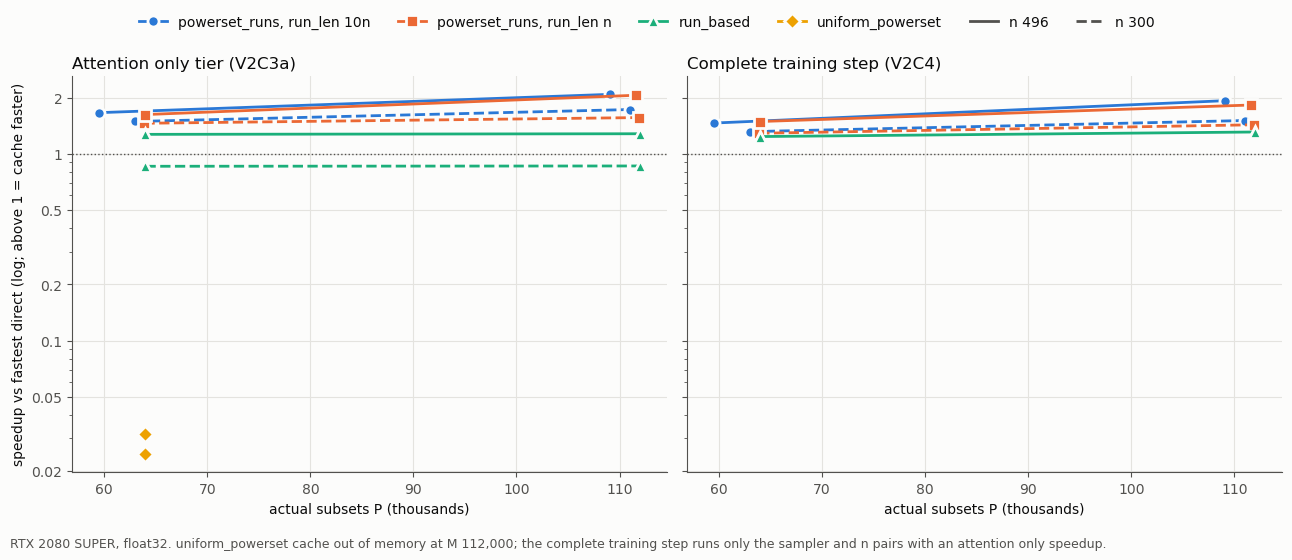

FIGURE 1 DATA (speedup_vs_best = fastest direct median / cache median):
                  tier          sampler run_len   n      M      P cache_status  cache_ms           best_direct  best_direct_ms  speedup_vs_best
attention only (V2C3a)    powerset_runs     10n 300  64000  63000           ok   106.530 sdpa_masked_math@4096         158.588            1.489
attention only (V2C3a)    powerset_runs     10n 300 112000 111000           ok   161.554 sdpa_masked_math@4096         278.631            1.725
attention only (V2C3a)    powerset_runs     10n 496  64000  59520           ok   130.586 sdpa_masked_math@4096         216.723            1.660
attention only (V2C3a)    powerset_runs     10n 496 112000 109120           ok   190.610 sdpa_masked_math@4096         396.453            2.080
attention only (V2C3a)    powerset_runs       n 300  64000  63900           ok   117.370 sdpa_masked_math@1024         170.935            1.456
attention only (V2C3a)    powerset_runs       n 300 112000 11190

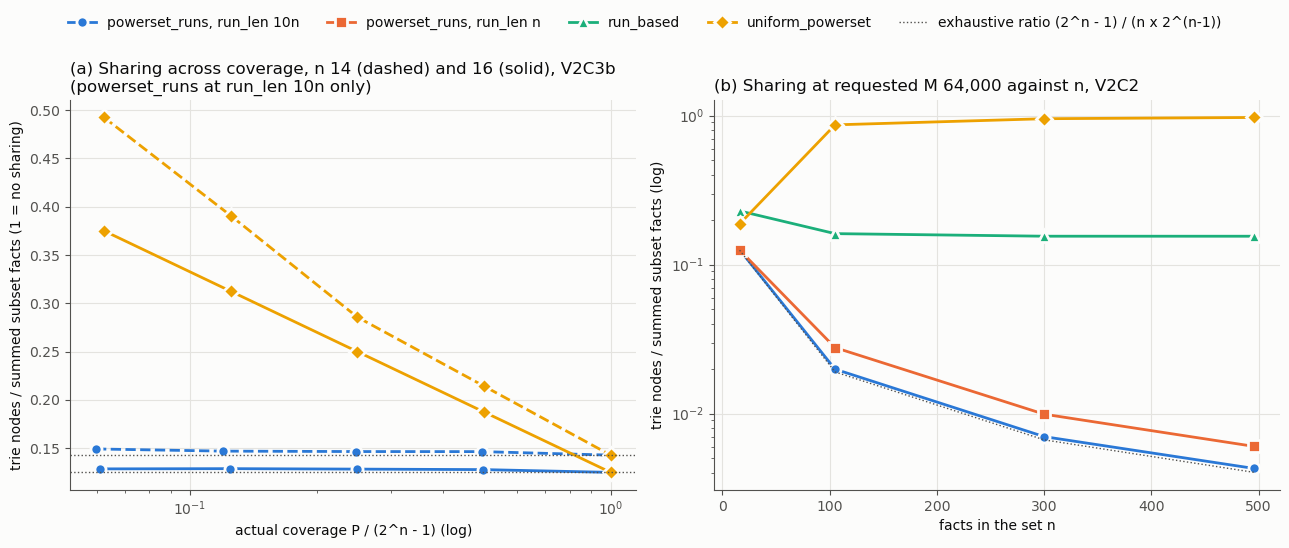

FIGURE 2 DATA (a), V2C3b:
         sampler  run_len  n coverage_target     M     P  coverage  nodes_over_facts
uniform_powerset      NaN 14            1/16  1024  1024    0.0625            0.4923
   powerset_runs    140.0 14            1/16  1024   980    0.0598            0.1492
uniform_powerset      NaN 14             1/8  2048  2048    0.1250            0.3907
   powerset_runs    140.0 14             1/8  2048  1960    0.1196            0.1470
uniform_powerset      NaN 14             1/4  4096  4096    0.2500            0.2857
   powerset_runs    140.0 14             1/4  4096  4060    0.2478            0.1466
uniform_powerset      NaN 14             1/2  8192  8192    0.5000            0.2143
   powerset_runs    140.0 14             1/2  8192  8120    0.4956            0.1465
uniform_powerset      NaN 14             1/1 16383 16383    1.0000            0.1428
   powerset_runs    140.0 14             1/1 16383 16383    1.0000            0.1428
uniform_powerset      NaN 16           

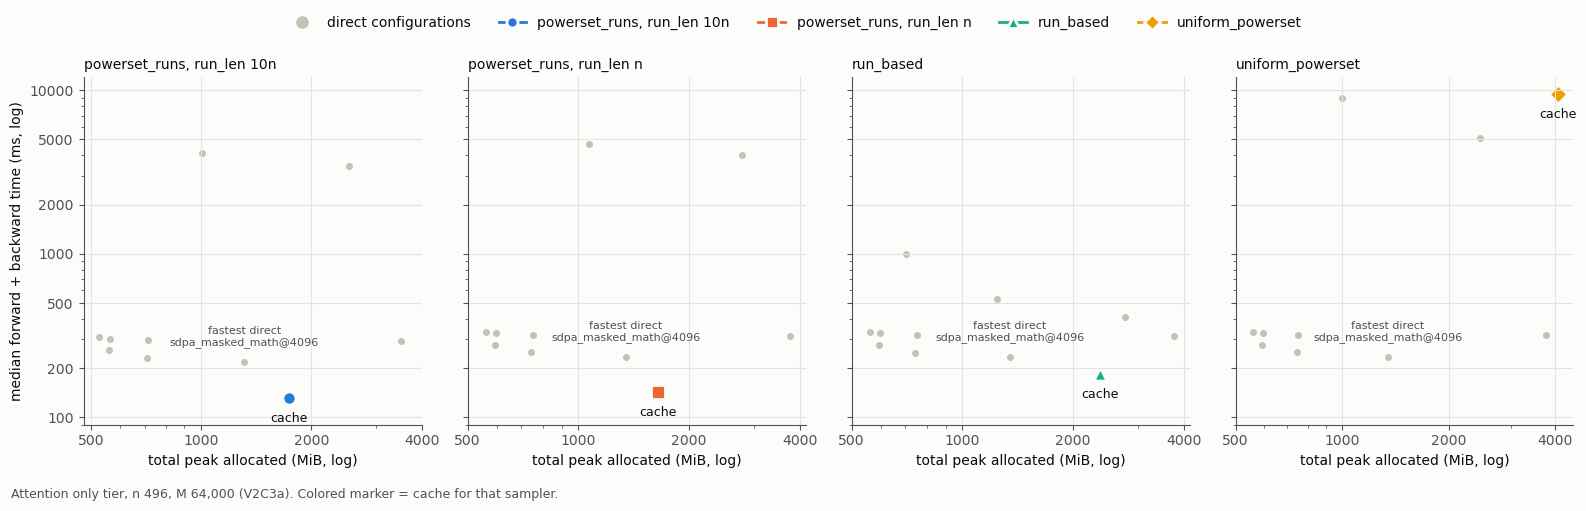

FIGURE 3 DATA:
         sampler run_len     P             impl chunk  t_median_ms  peak_alloc_MiB
   powerset_runs     10n 59520            cache   all        130.6          1732.4
   powerset_runs     10n 59520 sdpa_masked_math  4096        216.7          1310.9
   powerset_runs     10n 59520 sdpa_masked_math  1024        231.4           709.4
   powerset_runs     10n 59520 sdpa_masked_math   256        256.9           559.7
   powerset_runs     10n 59520      sdpa_masked   all        293.1          3504.8
   powerset_runs     10n 59520      sdpa_masked  4096        295.1           717.1
   powerset_runs     10n 59520      sdpa_masked  1024        302.4           563.1
   powerset_runs     10n 59520      sdpa_masked   256        310.3           524.7
   powerset_runs     10n 59520  direct_gathered  1024       3433.7          2536.5
   powerset_runs     10n 59520  direct_gathered   256       4158.3          1003.7
   powerset_runs       n 63984            cache   all        143.6      

In [8]:
# V2C5. Figures and claims. Reads pvcb_results_v2.pkl.lz4 only; no new measurement, nothing written.
# Every figure is followed by the table of the values it plots.
# Figure 1: speedup_vs_best against actual subsets P, per sampler and n: attention only tier (V2C3a) and complete
#           training step (V2C4); reference line at 1 (above = cache faster).
# Figure 2: sharing. (a) nodes / facts against actual coverage, n 14 and 16 (V2C3b); (b) nodes / facts against n at
#           requested M 64,000 (V2C2); both with the exhaustive ratio (2^n - 1) / (n x 2^(n-1)).
# Figure 3: median time against total peak memory for every configuration at n 496, M 64,000 (V2C3a), one panel
#           per sampler: the cache and the 12 direct configurations.
# Claims: C1 to C5 from the saved results, one block per claim.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
from apriori.serialization import load_from_pickle

RESULTS = r"E:\apriori-ml\notebooks\pvcb_results_v2.pkl.lz4"
store = load_from_pickle(RESULTS)
need = ("env", "equivalence", "certified_configs", "sampler_cert", "sampler_reuse", "v2c3a_rows", "v2c3a_points",
        "v2c3b_rows", "v2c3b_points", "v2c4_rows", "v2c4_points", "v2c4_env")
missing = [k for k in need if k not in store]
assert not missing, f"results file is missing {missing}"
assert store["v2c4_env"]["launch_mode"] == "asynchronous"

# ----- style: fixed series colors and markers, text in ink colors -----
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {("powerset_runs", "10n"): ("#2a78d6", "o", "powerset_runs, run_len 10n"),
          ("powerset_runs", "n"): ("#eb6834", "s", "powerset_runs, run_len n"),
          ("run_based", None): ("#1baf7a", "^", "run_based"),
          ("uniform_powerset", None): ("#eda100", "D", "uniform_powerset")}
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 2, "lines.markersize": 8, "font.size": 10})
EXH_HANDLE = Line2D([], [], color=INK2, lw=1, ls=":", label="exhaustive ratio (2^n - 1) / (n x 2^(n-1))")

def series_handles():
    return [Line2D([], [], color=c, marker=m, lw=2, markeredgecolor=SURF, markeredgewidth=2, label=l)
            for c, m, l in SERIES.values()]

def rl_label(row):
    rl, n = row.get("run_len"), row["n"]
    if rl is None or (isinstance(rl, float) and np.isnan(rl)):
        return None
    return "n" if int(rl) == int(n) else ("10n" if int(rl) == 10 * int(n) else str(int(rl)))

def summarize(rows, keys):
    """Per point: cache median ms, fastest feasible direct median ms and configuration, speedup, memory."""
    g = pd.DataFrame(rows)
    out = []
    for key, sel in g.groupby(keys, dropna=False):
        c = sel[sel["impl"] == "cache"].iloc[0]
        d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
        best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
        low = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
        ok = c["status"] == "ok" and best is not None
        out.append({**dict(zip(keys, key)), "P": int(c["P"]), "cache_status": c["status"],
                    "cache_ms": c["t_median_ms"], "best_direct": None if best is None else f"{best['impl']}@{best['chunk']}",
                    "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                    "speedup_vs_best": best["t_median_ms"] / c["t_median_ms"] if ok else np.nan,
                    "cache_total_MiB": c["peak_alloc_MiB"],
                    "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                    "lowest_direct_total_MiB": np.nan if low is None else low["peak_alloc_MiB"]})
    return pd.DataFrame(out)

a = pd.DataFrame(store["v2c3a_rows"])
a["rl"] = a.apply(rl_label, axis=1)
sa = summarize(a.assign(rl=a["rl"].fillna("none")).to_dict("records"), ["sampler", "rl", "n", "M"])
sa["rl"] = sa["rl"].replace("none", None)
c4 = pd.DataFrame(store["v2c4_rows"])
c4["rl"] = c4["run_len_label"]
s4 = summarize(c4.assign(rl=c4["rl"].fillna("none")).to_dict("records"), ["sampler", "rl", "n_target", "M"])
s4["rl"] = s4["rl"].replace("none", None)
s4 = s4.rename(columns={"n_target": "n"})

# ===== Figure 1: speedup against P =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, s, title in ((axes[0], sa, "Attention only tier (V2C3a)"), (axes[1], s4, "Complete training step (V2C4)")):
    for (smp, rl), (col, mk, lab) in SERIES.items():
        for n, ls in ((300, "--"), (496, "-")):
            sel = s[(s["sampler"] == smp) & (s["rl"].fillna("none") == (rl or "none")) & (s["n"] == n)
                    & s["speedup_vs_best"].notna()].sort_values("P")
            if len(sel):
                ax.plot(sel["P"] / 1000, sel["speedup_vs_best"], ls=ls, marker=mk, color=col,
                        markeredgecolor=SURF, markeredgewidth=2)
    ax.axhline(1.0, color=INK2, lw=1, ls=":")
    ax.set_yscale("log")
    ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5, 1, 2])
    ax.set_yticklabels(["0.02", "0.05", "0.1", "0.2", "0.5", "1", "2"])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("actual subsets P (thousands)")
    ax.set_title(title, color=INK, loc="left")
axes[0].set_ylabel("speedup vs fastest direct (log; above 1 = cache faster)")
handles = series_handles()
handles += [Line2D([], [], color=INK2, ls="-", label="n 496"), Line2D([], [], color=INK2, ls="--", label="n 300")]
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.text(0.01, 0.01, "RTX 2080 SUPER, float32. uniform_powerset cache out of memory at M 112,000; the complete "
         "training step runs only the sampler and n pairs with an attention only speedup.", color=INK2, fontsize=9)
plt.tight_layout(rect=(0, 0.04, 1, 0.93))
plt.show()
print("FIGURE 1 DATA (speedup_vs_best = fastest direct median / cache median):")
tab1 = pd.concat([sa.assign(tier="attention only (V2C3a)"), s4.assign(tier="complete step (V2C4)")])
with pd.option_context("display.width", 250):
    print(tab1[["tier", "sampler", "rl", "n", "M", "P", "cache_status", "cache_ms", "best_direct", "best_direct_ms",
                "speedup_vs_best"]].rename(columns={"rl": "run_len"}).round(3).to_string(index=False))

# ===== Figure 2: sharing =====
b = pd.DataFrame(store["v2c3b_points"])
r = pd.DataFrame(store["sampler_reuse"])
r["rl"] = r.apply(rl_label, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ax = axes[0]
for (smp, rl), (col, mk, lab) in SERIES.items():
    if smp == "powerset_runs" and rl != "10n":
        continue
    for n, ls in ((14, "--"), (16, "-")):
        sel = b[(b["sampler"] == smp) & (b["n"] == n)].sort_values("coverage")
        if len(sel):
            ax.plot(sel["coverage"], sel["nodes_over_facts"], ls=ls, marker=mk, color=col,
                    markeredgecolor=SURF, markeredgewidth=2)
for n in (14, 16):
    ax.axhline((2 ** n - 1) / (n * 2 ** (n - 1)), color=INK2, lw=1, ls=":")
ax.set_xscale("log")
ax.set_xlabel("actual coverage P / (2^n - 1) (log)")
ax.set_ylabel("trie nodes / summed subset facts (1 = no sharing)")
ax.set_title("(a) Sharing across coverage, n 14 (dashed) and 16 (solid), V2C3b\n"
             "(powerset_runs at run_len 10n only)", color=INK, loc="left")
ax = axes[1]
for (smp, rl), (col, mk, lab) in SERIES.items():
    sel = r[(r["sampler"] == smp) & (r["rl"].fillna("none") == (rl or "none"))].sort_values("n")
    if len(sel):
        ax.plot(sel["n"], sel["nodes_over_facts"], marker=mk, color=col, markeredgecolor=SURF, markeredgewidth=2)
ns = np.array([16, 105, 300, 496])
ax.plot(ns, (2.0 ** ns - 1) / (ns * 2.0 ** (ns - 1)), color=INK2, lw=1, ls=":")
ax.set_yscale("log")
ax.set_xlabel("facts in the set n")
ax.set_ylabel("trie nodes / summed subset facts (log)")
ax.set_title("(b) Sharing at requested M 64,000 against n, V2C2", color=INK, loc="left")
fig.legend(handles=series_handles() + [EXH_HANDLE], loc="upper center", ncol=5, frameon=False,
           bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
print("FIGURE 2 DATA (a), V2C3b:")
print(b[["sampler", "run_len", "n", "coverage_target", "M", "P", "coverage", "nodes_over_facts"]].round(4).to_string(index=False))
print("FIGURE 2 DATA (b), V2C2:")
print(r[["sampler", "run_len", "n", "M_requested", "P", "nodes_over_facts", "exhaustive_ratio"]].round(5).to_string(index=False))

# ===== Figure 3: time against memory, n 496, M 64,000 =====
sel_all = a[(a["n"] == 496) & (a["M"] == 64000) & (a["status"] == "ok")]
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
for ax, key in zip(axes, SERIES):
    smp, rl = key
    col, mk, lab = SERIES[key]
    sel = sel_all[(sel_all["sampler"] == smp) & (sel_all["rl"].fillna("none") == (rl or "none"))]
    d = sel[sel["impl"] != "cache"]
    c = sel[sel["impl"] == "cache"]
    ax.scatter(d["peak_alloc_MiB"], d["t_median_ms"], s=50, color="#c3c2b7", edgecolor=SURF, linewidth=2)
    ax.scatter(c["peak_alloc_MiB"], c["t_median_ms"], s=90, color=col, marker=mk, edgecolor=SURF, linewidth=2)
    if len(d):
        bst = d.loc[d["t_median_ms"].idxmin()]
        ax.annotate(f"fastest direct\n{bst['impl']}@{bst['chunk']}", (bst["peak_alloc_MiB"], bst["t_median_ms"]),
                    xytext=(0, 10), textcoords="offset points", ha="center", va="bottom", color=INK2, fontsize=8)
    if len(c):
        ax.annotate("cache", (c["peak_alloc_MiB"].iloc[0], c["t_median_ms"].iloc[0]), xytext=(0, -10),
                    textcoords="offset points", ha="center", va="top", color=INK, fontsize=9)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks([500, 1000, 2000, 4000])
    ax.set_xticklabels(["500", "1000", "2000", "4000"])
    ax.set_yticks([100, 200, 500, 1000, 2000, 5000, 10000])
    ax.set_yticklabels(["100", "200", "500", "1000", "2000", "5000", "10000"])
    ax.set_ylim(90, 12000)
    ax.set_xlabel("total peak allocated (MiB, log)")
    ax.set_title(lab, color=INK, loc="left", fontsize=10)
axes[0].set_ylabel("median forward + backward time (ms, log)")
fig.legend(handles=[Line2D([], [], ls="", marker="o", color="#c3c2b7", label="direct configurations")]
           + series_handles(), loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.text(0.01, 0.01, "Attention only tier, n 496, M 64,000 (V2C3a). Colored marker = cache for that sampler.",
         color=INK2, fontsize=9)
plt.tight_layout(rect=(0, 0.04, 1, 0.92))
plt.show()
print("FIGURE 3 DATA:")
with pd.option_context("display.width", 250):
    print(sel_all[["sampler", "rl", "P", "impl", "chunk", "t_median_ms", "peak_alloc_MiB"]]
          .rename(columns={"rl": "run_len"}).sort_values(["sampler", "run_len", "t_median_ms"]).round(1).to_string(index=False))

# ===== Claims =====
eq = store["equivalence"]
e64 = eq[eq["dtype"] == "float64"]
e32 = eq[eq["dtype"] == "float32"]
cert = store["sampler_cert"]
g4 = pd.DataFrame(store["v2c4_rows"])
pr_a = sa[sa["sampler"] == "powerset_runs"]["speedup_vs_best"]
rb_a = sa[(sa["sampler"] == "run_based") & (sa["n"] == 496)]["speedup_vs_best"]
rb3_a = sa[(sa["sampler"] == "run_based") & (sa["n"] == 300)]["speedup_vs_best"]
up_all = sa[sa["sampler"] == "uniform_powerset"]
up_a = up_all["speedup_vs_best"].dropna()
up_oom = int((up_all["cache_status"] == "oom").sum())
pr_4 = s4[s4["sampler"] == "powerset_runs"]["speedup_vs_best"]
rb_4 = s4[s4["sampler"] == "run_based"]["speedup_vs_best"]
mem_large = sa[sa["cache_status"] == "ok"]
bp = b[(b["sampler"] == "powerset_runs") & (b["coverage"] < 1.0)]
gap_b = bp["nodes_over_facts"] / ((2.0 ** bp["n"] - 1) / (bp["n"] * 2.0 ** (bp["n"] - 1))) - 1
rr = r[(r["sampler"] == "powerset_runs") & (r["rl"] == "10n") & (r["n"] >= 105)]
gap_r = rr["nodes_over_facts"] / rr["exhaustive_ratio"] - 1
bf = b[b["coverage"] == 1.0]
full_diff = float((bf["nodes_over_facts"] - (2.0 ** bf["n"] - 1) / (bf["n"] * 2.0 ** (bf["n"] - 1))).abs().max())
claims = [
    ("C1 exactness", "supported",
     f"V2C1: {int((eq['status'] == 'ok').sum())} of {len(eq)} comparisons within tolerance, 0 failures; "
     f"largest float64 error {np.nanmax(e64[['err_out', 'err_grad_q', 'err_grad_K', 'err_grad_V']].to_numpy()):.1e}; "
     f"largest float32 gradient relative difference {np.nanmax(e32[['err_grad_q', 'err_grad_K', 'err_grad_V']].to_numpy()):.1e}; "
     f"V2C4 complete step gradients within {g4['grad_rel_all'].max():.1e} of the reference"),
    ("C2 memory", "not supported",
     f"large set points (V2C3a): cache total peak above the fastest direct configuration at "
     f"{int((mem_large['cache_total_MiB'] > mem_large['best_direct_total_MiB']).sum())} of {len(mem_large)} "
     f"feasible points and above the lowest memory direct configuration at "
     f"{int((mem_large['cache_total_MiB'] > mem_large['lowest_direct_total_MiB']).sum())} of {len(mem_large)}"),
    ("C3 time, attention only",
     "supported for powerset_runs at every large set point and for run_based at n 496; not supported for "
     "run_based at n 300, for uniform_powerset, or at n 14 and 16",
     f"powerset_runs {pr_a.min():.2f}x to {pr_a.max():.2f}x (8 points, n 300 and 496, M 64,000 and 112,000); "
     f"run_based n 496 {rb_a.min():.2f}x to {rb_a.max():.2f}x; run_based n 300 {rb3_a.min():.3f}x to {rb3_a.max():.3f}x; "
     f"uniform_powerset {up_a.min():.2f}x to {up_a.max():.2f}x at M 64,000 and cache out of memory at {up_oom} of "
     f"{len(up_all)} points (M 112,000); cache slower at n 14 and 16 (V2C3b)"),
    ("C3 time, complete step", "supported at every point run (each sampler and n with an attention only speedup)",
     f"powerset_runs {pr_4.min():.2f}x to {pr_4.max():.2f}x (8 points); run_based n 496 "
     f"{rb_4.min():.2f}x to {rb_4.max():.2f}x (2 points)"),
    ("C4 reuse", "supported",
     f"powerset_runs within {100 * gap_b.max():.1f}% of the exhaustive ratio at every partial coverage (V2C3b, "
     f"n 14 and 16); run_len 10n within {100 * gap_r.min():.0f}% to {100 * gap_r.max():.0f}% at n 105 to 496 "
     f"(V2C2); at full coverage both samplers' ratios equal the counting formula (largest difference {full_diff:.1e})"),
    ("C5 sampler validity", "supported",
     f"{len(cert)} (n, M, run_len) cases, every offset: inclusion exactly P / T under a uniform offset"),
]
print("\nV2C5 CLAIMS (RTX 2080 SUPER, float32):")
for claim, status, evidence in claims:
    print(f"\n{claim}\n  status: {status}\n  evidence: {evidence}")

## V2C6. Counting checks for the prefix theorems (deterministic enumeration, CPU, no measurement)

Checks the counting statements the paper proves, on the actual enumerations the library produces, including the boundary cases that break the naive version of Theorem 4.

**Printed: `ORDER CHECK`:** the recursive prefix closed enumeration used here equals `unrank_lex_subset` rank by rank for n 2 to 12 (`identical` True).

**Printed: `THEOREM 2 AND 3`:** per n, the trie node count of the exhaustive fixed size lexicographic sweep against C(n + 1, k) − 1 for every k, and of the exhaustive power set against 2^n − 1; `all_equal` must be True.

**Printed: `THEOREM 4, ALL RUNS`:** for n 3 to 10, every contiguous nonwrapping run (every start, every length): `violations` of N(run) ≤ P + |f| − 1 (must be 0), `tight` (runs where equality holds), and the largest realized reuse ratio against the exhaustive ratio, which is where the naive corollary fails.

**Printed: `THEOREM 4, ADVERSARIAL`:** the first run, the last run, and a run wrapping the end of the order for n 10, 16, 20 and a selected set of lengths: `P`, `nodes`, `bound`, `ok`, `summed_facts`, `ratio`, `ratio_over_exhaustive`; the counterexample at n 100 (the last 1,000 subsets, built by unranking) with its ratio of at least 0.10.

**Printed: `RATIO OF EXPECTATIONS`:** for n 4 to 10 and runs of length L from R evenly spaced entry points over every offset: the mean summed cardinality per run against L n / 2 (`equal` True by linearity), the mean of the realized ratio, and the ratio of expectations bound (2 / n)(1 + (n − 1)/L); shows the realized ratios scatter around a value the bound covers in expectation but not pointwise.

In [2]:
# V2C6. Counting checks for the prefix theorems: deterministic enumeration on the library's own orders. CPU only.
import os, sys
sys.path.insert(0, r"E:\apriori-ml")
import numpy as np
import pandas as pd
from math import comb
from itertools import combinations
from set_attention_cache import unrank_lex_subset, unrank_lex_combination

N_ORDER, N_T23, N_ALLRUNS, N_ADV, N_BIG, L_BIG = range(2, 13), range(2, 13), range(3, 11), (10, 16, 20), 100, 1000
ADV_LENGTHS = (1, 2, 5, 17, 100, 1000)
N_EXPECT, L_EXPECT, R_EXPECT = range(4, 11), (2, 4, 8, 16), 4

def powerset_prefix_order(n):
    """All nonempty subsets of range(n) in the prefix closed lexicographic order (each prefix precedes its extensions)."""
    out = []
    def rec(prefix, start):
        for e in range(start, n):
            s = prefix + (e,)
            out.append(s)
            rec(s, e + 1)
    rec((), 0)
    return out

def trie_nodes(subsets):
    nodes = set()
    for s in subsets:
        for j in range(1, len(s) + 1):
            nodes.add(s[:j])
    return len(nodes)

def exhaustive_ratio(n):
    return (2 ** n - 1) / (n * 2 ** (n - 1))

# ----- order check -----
rows = []
for n in N_ORDER:
    enum = powerset_prefix_order(n)
    same = all(tuple(unrank_lex_subset(r, n)) == enum[r] for r in range(len(enum)))
    rows.append({"n": n, "subsets": len(enum), "identical": same})
print("ORDER CHECK (recursive prefix closed order vs unrank_lex_subset)")
print(pd.DataFrame(rows).to_string(index=False))

# ----- theorems 2 and 3 -----
rows = []
for n in N_T23:
    ok_k = all(trie_nodes(list(combinations(range(n), k))) == comb(n + 1, k) - 1 for k in range(1, n + 1))
    ok_p = trie_nodes(powerset_prefix_order(n)) == 2 ** n - 1
    rows.append({"n": n, "fixed_k_all_equal": ok_k, "powerset_equal": ok_p, "all_equal": ok_k and ok_p})
print("\nTHEOREM 2 AND 3 (fixed k sweep nodes = C(n+1,k) - 1; power set nodes = 2^n - 1)")
print(pd.DataFrame(rows).to_string(index=False))

# ----- theorem 4, every nonwrapping run -----
rows = []
for n in N_ALLRUNS:
    enum = powerset_prefix_order(n)
    T = len(enum)
    viol = tight = 0
    worst = 0.0
    ex = exhaustive_ratio(n)
    for s in range(T):
        nodes = set()
        facts = 0
        f = enum[s]
        for L in range(1, T - s + 1):
            sub = enum[s + L - 1]
            for j in range(1, len(sub) + 1):
                nodes.add(sub[:j])
            facts += len(sub)
            bound = L + len(f) - 1
            if len(nodes) > bound:
                viol += 1
            if len(nodes) == bound:
                tight += 1
            worst = max(worst, len(nodes) / facts / ex)
    rows.append({"n": n, "runs_checked": T * (T + 1) // 2, "violations": viol, "tight": tight, "max_ratio_over_exhaustive": worst})
print("\nTHEOREM 4, ALL RUNS (N(run) <= P + |f| - 1 for every contiguous nonwrapping run)")
print(pd.DataFrame(rows).to_string(index=False))

# ----- theorem 4, adversarial runs -----
def run_stats(n, ranks):
    subs = [tuple(unrank_lex_subset(r, n)) for r in ranks]
    f = subs[0]
    return len(subs), trie_nodes(subs), len(subs) + len(f) - 1, sum(len(s) for s in subs)

rows = []
for n in N_ADV:
    T = 2 ** n - 1
    ex = exhaustive_ratio(n)
    for L in ADV_LENGTHS:
        if L > T:
            continue
        for label, ranks in (("first", list(range(0, L))), ("last", list(range(T - L, T)))):
            P, nodes, bound, facts = run_stats(n, ranks)
            rows.append({"n": n, "run": label, "P": P, "nodes": nodes, "bound": bound, "ok": nodes <= bound, "summed_facts": facts,
                         "ratio": nodes / facts, "ratio_over_exhaustive": nodes / facts / ex})
        half = L // 2
        if 0 < half < L and L <= T:                                   # wrapping run: last half of the order, then the first half
            ranks = list(range(T - half, T)) + list(range(0, L - half))
            subs = [tuple(unrank_lex_subset(r, n)) for r in ranks]
            nodes = trie_nodes(subs)
            bound = L + (len(subs[0]) - 1) + (len(subs[half]) - 1)    # two segments, each with its own first subset
            facts = sum(len(s) for s in subs)
            rows.append({"n": n, "run": "wrapping", "P": L, "nodes": nodes, "bound": bound, "ok": nodes <= bound, "summed_facts": facts,
                         "ratio": nodes / facts, "ratio_over_exhaustive": nodes / facts / ex})
T_big = 2 ** N_BIG - 1
P, nodes, bound, facts = run_stats(N_BIG, list(range(T_big - L_BIG, T_big)))
rows.append({"n": N_BIG, "run": "last (counterexample)", "P": P, "nodes": nodes, "bound": bound, "ok": nodes <= bound, "summed_facts": facts,
             "ratio": nodes / facts, "ratio_over_exhaustive": nodes / facts / exhaustive_ratio(N_BIG)})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print("\nTHEOREM 4, ADVERSARIAL (first, last and wrapping runs; the n 100 last run is the counterexample to the naive corollary)")
print(pd.DataFrame(rows).to_string(index=False))

# ----- ratio of expectations under a uniform offset -----
rows = []
for n in N_EXPECT:
    enum = powerset_prefix_order(n)
    T = len(enum)
    for L in L_EXPECT:
        if R_EXPECT * L > T:
            continue
        stride = T // R_EXPECT
        facts_all, ratio_all, nodes_all = [], [], []
        for off in range(T):
            ranks = [(off + r * stride + j) % T for r in range(R_EXPECT) for j in range(L)]
            subs = [enum[r] for r in ranks]
            facts = sum(len(s) for s in subs)
            nodes = trie_nodes(subs)
            facts_all.append(facts); nodes_all.append(nodes); ratio_all.append(nodes / facts)
        ex = exhaustive_ratio(n)
        rows.append({"n": n, "L": L, "R": R_EXPECT, "mean_facts_per_run": np.mean(facts_all) / R_EXPECT, "L_over_exhaustive_ratio": L / ex,
                     "equal": abs(np.mean(facts_all) / R_EXPECT - L / ex) < 1e-9, "mean_nodes": np.mean(nodes_all),
                     "ratio_of_means": np.mean(nodes_all) / np.mean(facts_all), "mean_of_ratios": np.mean(ratio_all), "max_ratio": max(ratio_all),
                     "bound_ratio_of_expectations": ex * (1 + (n - 1) / L)})
print("\nRATIO OF EXPECTATIONS (uniform offset over every rotation; R runs of length L)")
print(pd.DataFrame(rows).to_string(index=False))
pd.reset_option("display.float_format")

ORDER CHECK (recursive prefix closed order vs unrank_lex_subset)
 n  subsets  identical
 2        3       True
 3        7       True
 4       15       True
 5       31       True
 6       63       True
 7      127       True
 8      255       True
 9      511       True
10     1023       True
11     2047       True
12     4095       True

THEOREM 2 AND 3 (fixed k sweep nodes = C(n+1,k) - 1; power set nodes = 2^n - 1)
 n  fixed_k_all_equal  powerset_equal  all_equal
 2               True            True       True
 3               True            True       True
 4               True            True       True
 5               True            True       True
 6               True            True       True
 7               True            True       True
 8               True            True       True
 9               True            True       True
10               True            True       True
11               True            True       True
12               True            True  

## V2C6 findings

**Order.** The recursive prefix closed enumeration equals `unrank_lex_subset` rank for rank at n 2 to 12 (4,095 subsets at n 12), so the theorems below are about the library's order.

**Theorems 2 and 3.** For n 2 to 12 and every k, the trie of the exhaustive fixed size lexicographic sweep has exactly C(n + 1, k) − 1 nodes, and the trie of the exhaustive power set has exactly 2^n − 1 nodes.

**Theorem 4 (prefix overhead), stated as an equality.** For every contiguous nonwrapping run of P subsets in the prefix closed order with first subset f, the trie has exactly P + |f| − 1 nodes: every run checked at n 3 to 10 (523,776 runs at n 10, every start and every length) is tight, with 0 violations. The missing nodes are the proper ancestors of f, which precede the run and are all needed. A wrapping run is two segments and has P + (|f1| − 1) + (|f2| − 1) nodes; the second segment starts at the root, so this is P + |f1| − 1 (all wrapping rows tight).

**The naive corollary is false.** The reuse ratio of a run is its node count over its summed cardinality, and the denominator depends on where the run sits. The last run of 1,000 subsets at n 100 has 1,007 nodes over 4,964 facts, a ratio of 0.2029, which is 10.1 times the exhaustive ratio; the same run at n 10, 16 and 20 gives 1.0, 1.6 and 2.0 times. Short runs at the start of the order sit below the exhaustive ratio (first 100 at n 20: 0.64 times) because their subsets are large. So Theorem 4 bounds nodes, and the ratio is stated against the family's actual mean cardinality: N(F) / Σ|S| = (1 + (|f| − 1)/L) / k̄ per run.

**Ratio of expectations.** Under a uniformly random offset every run position is marginally uniform over the nonempty subsets, whose mean size is n 2^(n−1) / (2^n − 1), so the expected summed cardinality of a run of length L is L / exhaustive_ratio (`equal` True at every n and L), and the ratio of expectations E[nodes] / E[facts] is at most exhaustive_ratio × (1 + (n − 1)/L). The table confirms `ratio_of_means` below that bound at every point, while `max_ratio` exceeds it from L 8 upward (n 10, L 16: 0.3795 against 0.3125). The bound holds in expectation, not pointwise, and the paper states it that way; the measured closeness of `powerset_runs` to the exhaustive ratio at n 105 to 496 (V2C2, within 1% to 6%) remains an empirical result.